# ⚽ Fußballspiele, Wetter & Geodaten
### Datenbeschreibung, Datenmodell und explorative Analyse – Top-5-Ligen 2014/15 bis 2025/26

---

**Worum geht es?**
Dieses Notebook beschreibt den angereicherten Datensatz `Match_statistics_enriched.parquet` und untersucht mit ihm **zwölf Fragen**:
- Acht Fragen betreffen den Einfluss von **Wetter und Geografie** auf Tore und Ergebnisse.
- Vier Fragen beziehen sich nur auf die **Understat-Spielstatistiken** und deren Entwicklung über die Zeit.

Das Ziel ist zu verstehen, welche Merkmale für ein **Vorhersage- und Value-Betting-Modell** wirklich Information tragen.

**Der Datensatz in Zahlen**

| | |
|---|---|
| Spiele | **21.589** |
| Ligen | Premier League, Serie A, Bundesliga, La Liga, Ligue 1 |
| Saisons | 12 (2014/15 – 2025/26) |
| Teams / Stadien | 168 / 163 |
| Spalten | 41 (davon 26 Understat, 8 Geo, 4 Wetter, 3 abgeleitet) |

**Aufbau**

| Abschnitt | Inhalt | Code? |
|---|---|---|
| 1 | Die drei Datenquellen | – |
| 2 | Wie die Daten zusammengeführt wurden | – |
| 3 | Datenmodell | – |
| 4 | Der Datensatz im Überblick | – |
| 5 | Zwölf Analysefragen | – |
| 6 | Beantwortung der Fragen anhand der Daten | ✔ |
| 7 | Fazit für das Wettmodell | – |

> **Hinweis:** Abschnitte 1–5 sind reiner Text mit Abbildungen. Code beginnt erst in Abschnitt 6. Dort wird die Parquet-Datei aus demselben Google-Drive-Ordner geladen, in dem auch dieses Notebook liegt.

## 1 · Die drei Datenquellen

Der Datensatz entsteht aus drei voneinander unabhängigen Quellen. Jede liefert eine andere Perspektive auf ein Spiel: **was** auf dem Platz passiert ist (Understat), **wo** es stattfand (Geodaten) und **unter welchen Bedingungen** (Wetter).


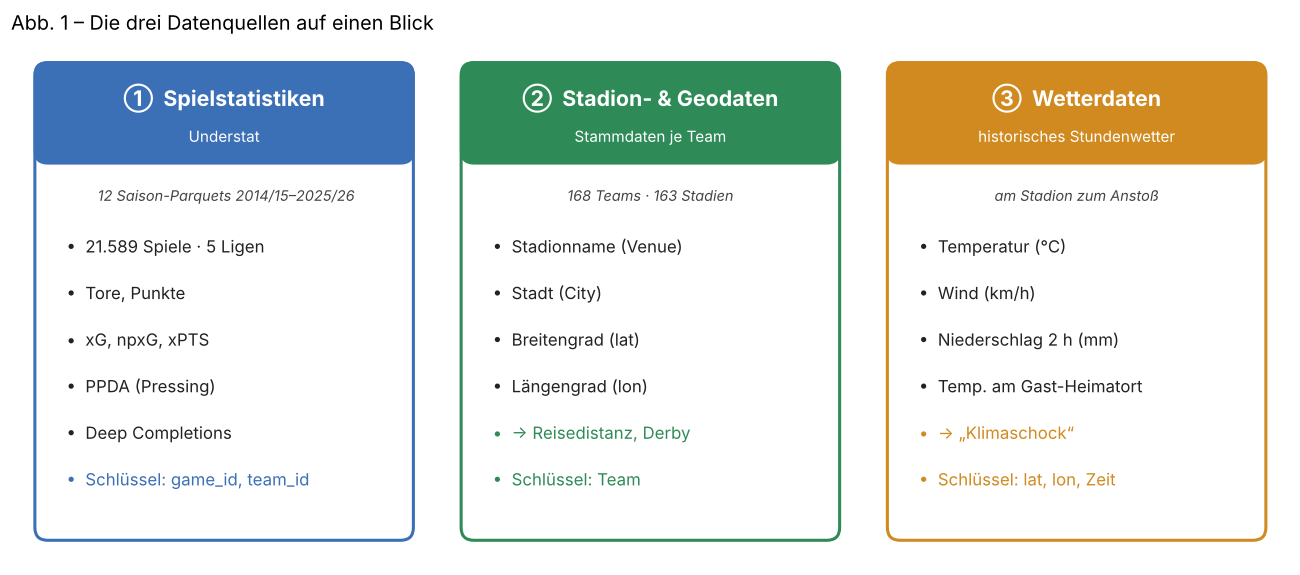

### Quelle ① – Spielstatistiken von Understat

[Understat](https://understat.com) berechnet für jedes Spiel der Top-5-Ligen fortgeschrittene Kennzahlen aus Schussdaten. Die Daten liegen als **eine Parquet-Datei pro Saison** vor (`Football stats 2014_2015.parquet` … `Football stats 2025_2026.parquet`). Die Herkunftsdatei steht in der Spalte `source_file`.

Jede Kennzahl gibt es zweimal, mit Präfix `home_` für das Heimteam und `away_` für das Gastteam:

| Kennzahl | Was sie misst | Warum sie interessant ist |
|---|---|---|
| `goals`, `points` | Tore, Punkte (3 / 1 / 0) | das tatsächliche Ergebnis |
| `xg` – *Expected Goals* | Summe der Torwahrscheinlichkeiten aller Schüsse. Ein Schuss mit xG 0,3 wird im Schnitt in 30 % der Fälle ein Tor | misst die **Qualität der Chancen** unabhängig vom Glück im Abschluss |
| `np_xg` | xG ohne Elfmeter | Elfmeter verzerren xG stark (≈ 0,76 pro Elfmeter) |
| `np_xg_difference` | eigenes npxG minus gegnerisches npxG | Dominanz im Spiel |
| `expected_points` – *xPTS* | erwartete Punkte, simuliert aus der xG-Verteilung beider Teams | „verdientes“ Ergebnis |
| `ppda` – *Passes per Defensive Action* | gegnerische Pässe pro eigener Defensivaktion im Angriffsdrittel und Mittelfeld | **niedrig = intensives Pressing**, hoch = abwartend |
| `deep_completions` | Pässe, die innerhalb von ca. 20 m vor dem gegnerischen Tor ankommen (ohne Flanken) | Durchschlagskraft im Angriff |

Dazu kommen Schlüssel und Metadaten: `game_id`, `league_id` (1 = EPL, 2 = Serie A, 3 = Bundesliga, 4 = La Liga, 5 = Ligue 1), `season_id` (Startjahr der Saison), `date` (Anstoßzeit), Team-IDs, Teamnamen und Kürzel.

### Quelle ② – Stadion- und Geodaten

Eine Stammdatentabelle ordnet **jedem Team sein Heimstadion** zu: Stadionname (`Venue`), Stadt (`City`) sowie Breiten- und Längengrad (`lat`, `lon`). 168 Teams teilen sich 163 Stadien. Fünf Stadien werden von zwei Vereinen genutzt, zum Beispiel das San Siro von AC Milan und Inter oder das Stadio Olimpico von Roma und Lazio.

Die Karte zeigt, wie unterschiedlich die Ligen geografisch aufgestellt sind. England ist kompakt, Spanien und Frankreich sind weitläufig, und Las Palmas auf den Kanaren ist ein extremer Ausreißer.


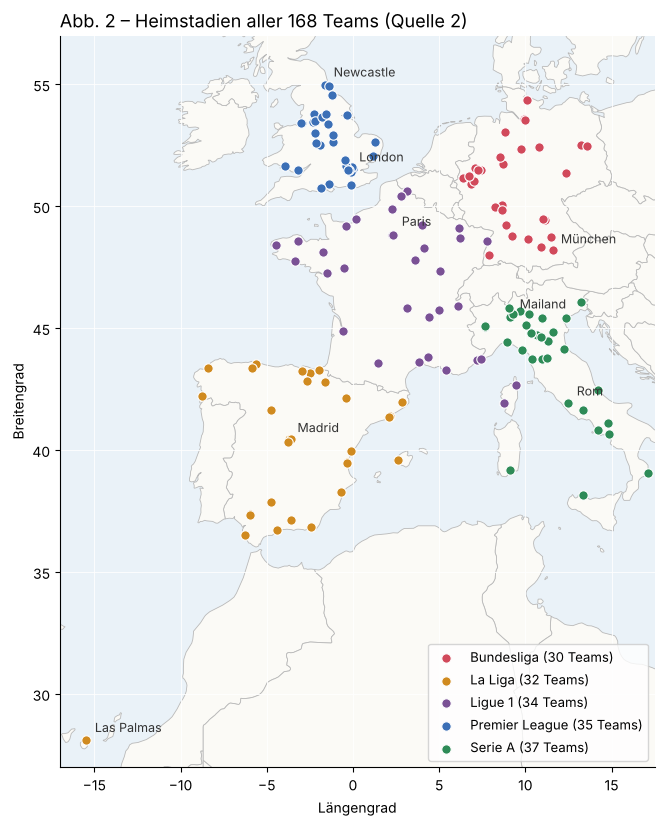

> ⚠️ **Einschränkung:** Pro Team ist nur *ein* Stadion hinterlegt, nämlich der aktuelle Stand. Stadionwechsel im Zeitraum, etwa bei Tottenham oder Everton, sind nicht historisiert.

### Quelle ③ – Historische Wetterdaten

Für jedes Spiel wurde das **stündliche Wetter am Stadion-Koordinatenpunkt zum Anstoßzeitpunkt** ermittelt, typischerweise über eine Wetter-Archiv-API wie Open-Meteo.

| Spalte | Bedeutung | Einheit |
|---|---|---|
| `w_temp` | Lufttemperatur am Spielort zum Anstoß | °C |
| `w_wind` | Windgeschwindigkeit am Spielort | km/h |
| `w_precip_2h` | Niederschlag, summiert über ca. 2 Stunden (Spieldauer) | mm |
| `w_temp_diff_away` | Temperatur am Spielort minus Temperatur am Heimatort des Gastteams zur gleichen Zeit | °C |

Die meisten Spiele finden bei mildem, trockenem Wetter statt. Extreme wie Frost, Sturm oder Starkregen sind selten. Das ist wichtig, weil Effekte in diesen Randbereichen auf kleinen Stichproben beruhen.


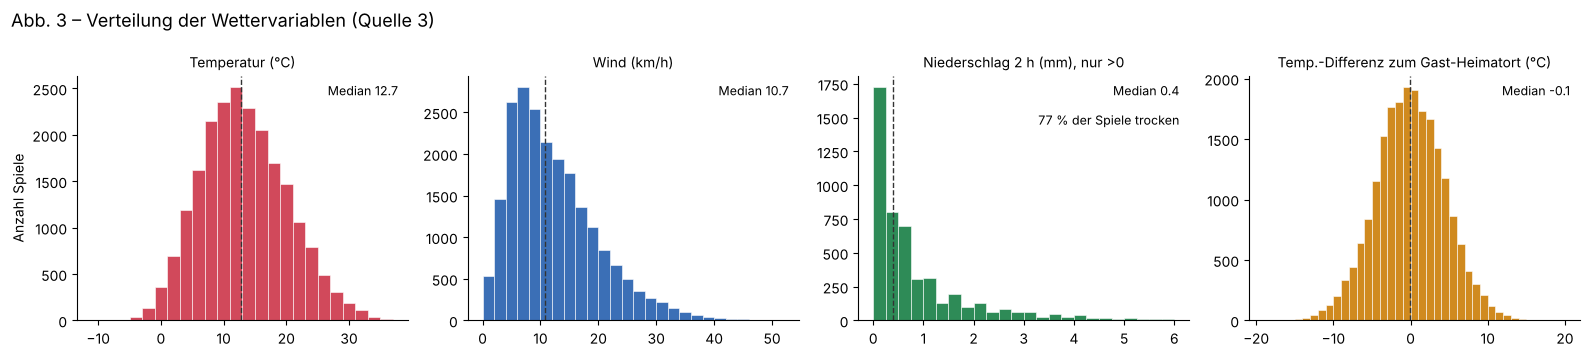

## 2 · Wie die Daten zusammengeführt wurden

Die Zusammenführung läuft in vier Schritten. Die Spieltabelle ist die Basis, alle anderen Informationen werden per **Left Join** angehängt. So geht kein Spiel verloren, auch wenn einmal Wetter- oder Geodaten fehlen.


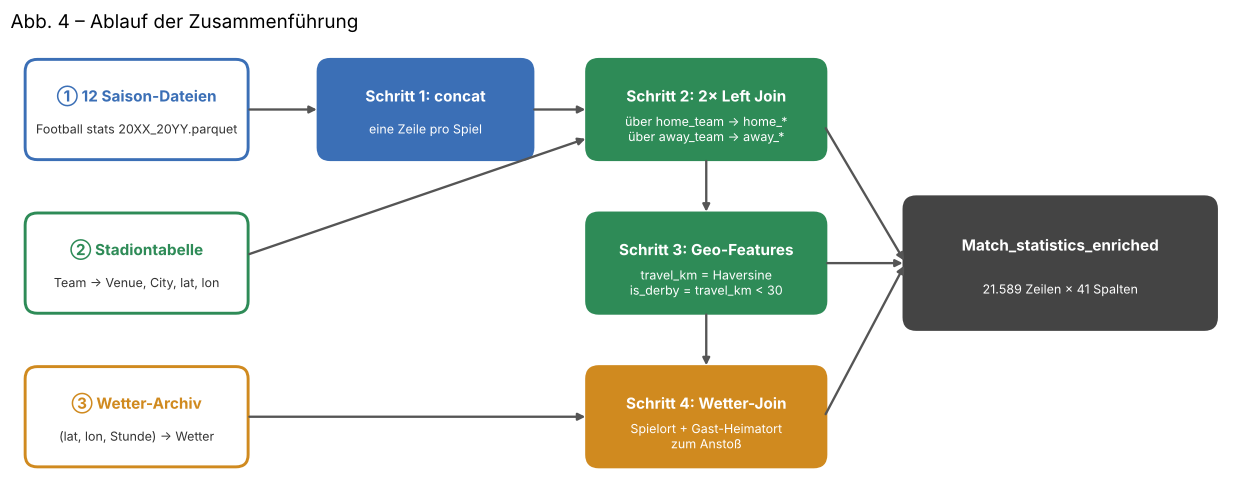

**Schritt 1 – Saisons stapeln (`concat`).** Die zwölf Understat-Dateien haben identische Spalten und werden untereinandergehängt. Ergebnis: eine Zeile pro Spiel, eindeutiger Schlüssel `game_id`.

**Schritt 2 – Geodaten zweimal anhängen.** Die Stadiontabelle wird **zweimal** gejoint:
- über `home_team` → Spalten `home_City`, `home_Venue`, `home_lat`, `home_lon` (= **Spielort**)
- über `away_team` → Spalten `away_City`, `away_Venue`, `away_lat`, `away_lon` (= **Heimatort des Gastes**)

**Schritt 3 – Geo-Features ableiten.**
- `travel_km`: Großkreisdistanz (Haversine-Formel) zwischen den beiden Stadien, also die Luftlinie, die das Gastteam anreist.
- `is_derby`: 1, wenn `travel_km < 30` gilt (Lokalderby, z. B. Arsenal–Tottenham, Milan–Inter mit 0 km).


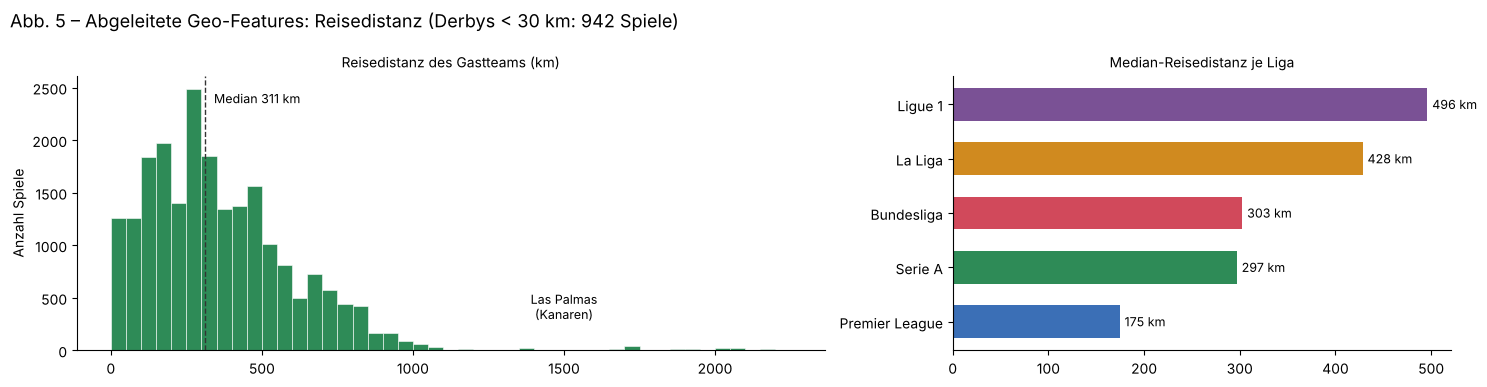

**Schritt 4 – Wetter anhängen.** Für jedes Spiel wird das Wetter über den Schlüssel *(home_lat, home_lon, Anstoß auf die Stunde gerundet)* zugeordnet. Zusätzlich wird die Temperatur am Gast-Heimatort *(away_lat, away_lon, gleiche Stunde)* abgefragt. Die Differenz ergibt `w_temp_diff_away`, also wie viel wärmer oder kälter es für das Gastteam ist als zu Hause.

**Datenqualität nach der Zusammenführung** (in Abschnitt 6 per Code geprüft):
- `travel_km` lässt sich per Haversine bis auf weniger als 0,1 km nachrechnen.
- Die Derby-Regel ist sauber: Derbys haben höchstens 29,9 km Anreise, alle anderen Spiele mindestens 31,1 km.
- Es fehlen nur 28 Werte bei `w_temp_diff_away` und je 2 bei PPDA.
- `game_id` ist eindeutig, es gibt keine doppelten Spiele.

**Beispiel – eine Zeile nach der Zusammenführung** (Arsenal – Crystal Palace, 16.08.2014):

| Quelle | Werte |
|---|---|
| ① Understat | 2:1, xG 1,55 : 0,16, PPDA 2,9 : 14,2, xPTS 2,79 : 0,11 |
| ② Geo | Emirates Stadium (51,56° N, −0,11° O) ← Selhurst Park (51,40° N, −0,09° O) |
| abgeleitet | travel_km = 17,5 → **is_derby = 1** |
| ③ Wetter | 17,6 °C, Wind 20,5 km/h, trocken, Temperaturdifferenz −2,4 °C |

## 3 · Datenmodell

Logisch handelt es sich um ein **Sternschema**:
- **MATCH** ist die Faktentabelle. Jede Zeile ist ein Spiel mit allen Kennzahlen beider Teams.
- **TEAM / STADIUM** ist eine Dimension, die **zweimal** referenziert wird: einmal als Heimteam (Spielort) und einmal als Gastteam (Heimatort des Gastes).
- **WEATHER** ist über die Koordinaten des Stadions und den Anstoßzeitpunkt mit dem Spiel verbunden.
- **LEAGUE** und **SEASON** sind kleine Lookup-Dimensionen.

Physisch ist alles in **einer flachen Tabelle** gespeichert. Das ist für Analyse und Machine Learning praktisch, weil keine Joins mehr nötig sind.


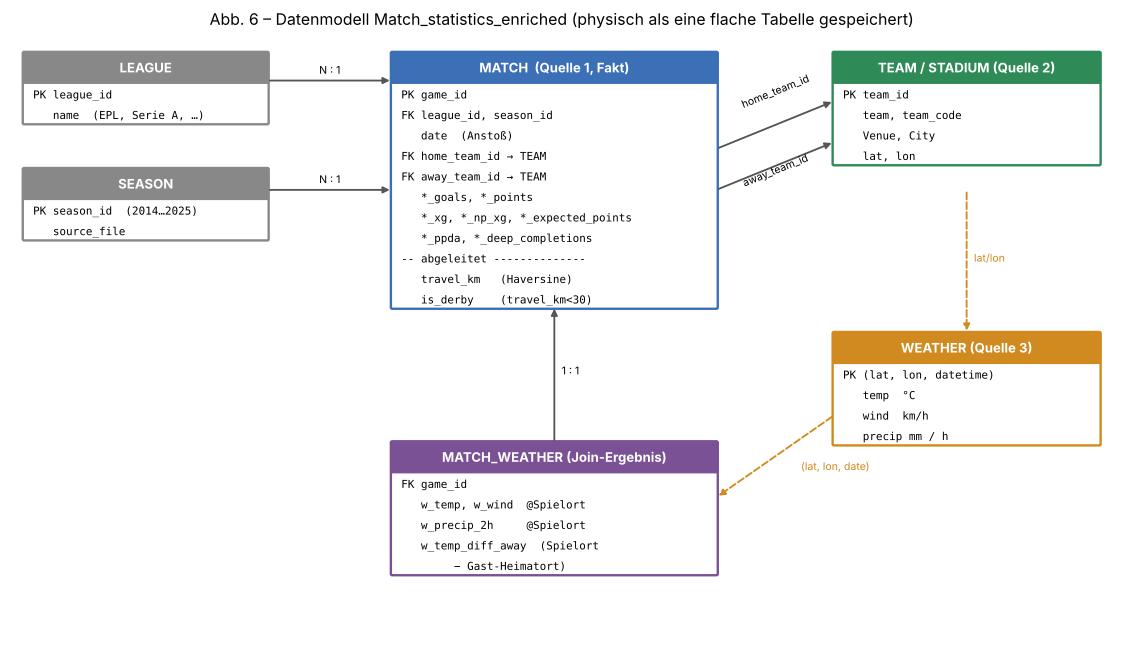

## 4 · Der Datensatz im Überblick


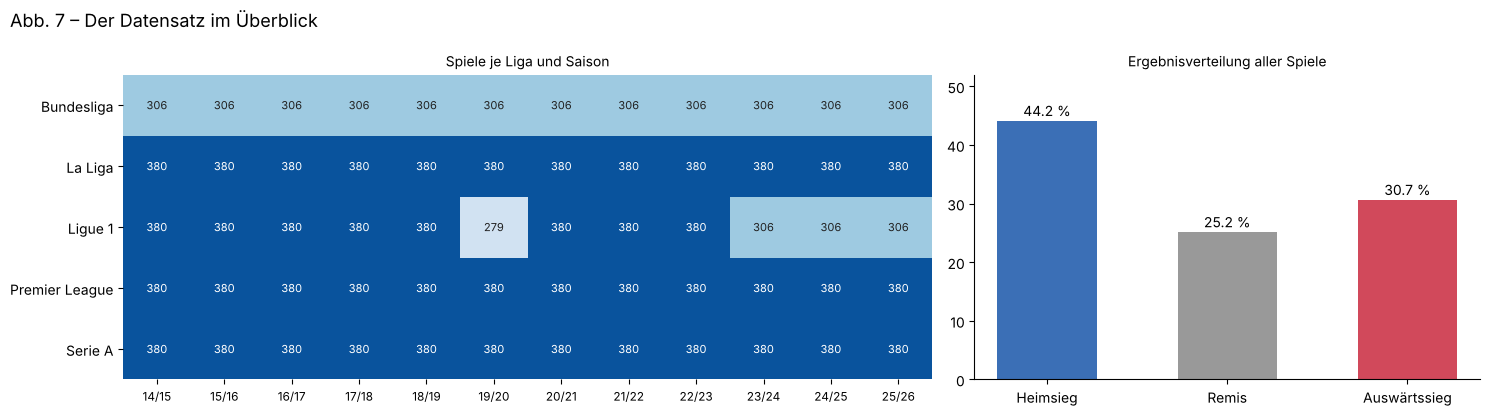

- Die Bundesliga spielt mit 18 Teams (306 Spiele pro Saison), die anderen Ligen mit 20 Teams (380).
- **Ligue 1 2019/20** wurde wegen Corona nach 279 Spielen abgebrochen. Seit 2023/24 spielt die Ligue 1 mit nur noch 18 Teams.
- Insgesamt gewinnt das Heimteam **44,2 %** der Spiele, 25,2 % enden remis, 30,7 % gewinnt der Gast. Dieser **Heimvorteil** ist der Bezugspunkt für viele der folgenden Fragen.

## 5 · Zwölf Analysefragen

### Teil A – Wetter & Geodaten (Quellen ② und ③)

| # | Frage | Zielgröße | Merkmal |
|---|---|---|---|
| F1 | Hat die **Temperatur** einen Einfluss auf die Anzahl der Tore? | Tore, Over 2.5 | `w_temp` |
| F2 | Fallen bei **Regen** mehr oder weniger Tore? | Tore, xG | `w_precip_2h` |
| F3 | Senkt **starker Wind** die Torzahl und die Chancenqualität (xG)? | Tore, xG gesamt | `w_wind` |
| F4 | Beeinflusst das **Wetter den Sieger** (Heimsieg / Remis / Auswärtssieg)? | 1X2 | alle Wettervariablen |
| F5 | Bestimmt die **Reisedistanz** die Heimstärke einer Mannschaft? | Heimsieg, Auswärtspunkte | `travel_km` |
| F6 | Verändert eine **weite Anreise den Spielstil** des Gastes? | PPDA, xG des Gastes | `travel_km` |
| F7 | Sind **Derbys** anders – weniger Heimvorteil, weniger Tore? | 1X2, Tore | `is_derby` |
| F8 | Gibt es ein **Nord-Süd-Gefälle** im Heimvorteil, und leidet der Gast unter einem **Klimaschock**? | Heimsieg | `home_lat`, `w_temp_diff_away` |

### Teil B – Nur Understat-Daten, über den gesamten Zeitverlauf (Quelle ①)

| # | Frage | Zielgröße | Merkmal |
|---|---|---|---|
| F9 | Wie hat sich der **Heimvorteil von 2014 bis 2025** entwickelt, und welche Rolle spielten die Geisterspiele? | Heimsieg-%, Punkte- und xG-Differenz | `season_id`, Datum |
| F10 | Fallen heute **mehr Tore** als 2014? Steigt die **Chancenqualität (xG)** mit, oder treffen die Teams einfach besser? | Tore, xG, Tore − xG | `season_id`, Liga |
| F11 | Hat sich das **Pressing (PPDA)** über die Jahre verändert, und **gewinnen Pressing-Teams häufiger**? | PPDA, Punkte | `ppda`, xG-Differenz |
| F12 | Ist **xG/xPTS ein besserer Prädiktor als die Tabelle**? Kehren Teams, die über ihren xPTS punkten, zum Mittelwert zurück? | Punkte der Rückrunde | Punkte vs. xPTS der Hinrunde |

**Methodik:**
- **Teil A:** Zuerst wird jede Frage deskriptiv betrachtet (Gruppen bilden, Quoten vergleichen, Chi²-Test). Danach folgt eine **Regression mit Kontrollvariablen**:
  - Teamstärke (Differenz der Saison-Durchschnitte der xG-Differenz von Heim- und Gastteam)
  - Liga (fixe Effekte)
  - Geisterspiele (März 2020 – Juni 2021)

  Ohne diese Kontrollen würde man Scheineffekte messen: Weite Anreisen betreffen zum Beispiel vor allem bestimmte Ligen und Teams.
- **Teil B:** Zeitreihen je Saison und Liga, Trendtests (lineare Regression über die Saisons) und Analysen auf Team-Saison-Ebene.

## 6 · Beantwortung der Fragen anhand der Daten

### 6.0 · Daten laden & vorbereiten

Die Parquet-Datei liegt im **selben Google-Drive-Ordner wie dieses Notebook**. Trage den Ordnerpfad bei `DRIVE_ORDNER` ein. Falls die Datei dort nicht gefunden wird, durchsucht die Zelle automatisch das ganze „Meine Ablage“.

In [20]:

import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import chi2_contingency
import warnings; warnings.filterwarnings('ignore')

FILE_NAME    = 'Match_statistics_enriched.parquet'
DRIVE_ORDNER = '/content/drive/MyDrive/Uni/2. Semester/WI-AA'

try:
    from google.colab import drive
    drive.mount('/content/drive')

    PATH = os.path.join(DRIVE_ORDNER, FILE_NAME)

    if not os.path.exists(PATH):
        print(f'Datei nicht unter Standardpfad gefunden. Suche in Google Drive ...')

        treffer = glob.glob(
            f'/content/drive/**/{FILE_NAME}',
            recursive=True
        )

        if not treffer:
            raise FileNotFoundError(
                f'{FILE_NAME} wurde in Google Drive nicht gefunden. '
                'Bitte prüfen, ob der geteilte Ordner in Google Drive eingebunden ist '
                'und die Datei zugänglich ist.'
            )

        PATH = treffer[0]

except ImportError:          # außerhalb von Colab: Datei im aktuellen Ordner
    PATH = FILE_NAME

raw = pd.read_parquet(PATH)
print(f'Geladen: {os.path.basename(PATH)} → {raw.shape[0]:,} Spiele × {raw.shape[1]} Spalten'.replace(',', '.'))

pd.set_option('display.width', 160, 'display.max_columns', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#eeeeee', 'axes.axisbelow': True})
BLUE, GREY = '#3b6fb6', '#999999'
LCOL = {'EPL': '#3b6fb6', 'Serie A': '#2e8b57', 'Bundesliga': '#d1495b', 'La Liga': '#d08a1f', 'Ligue 1': '#7a5195'}


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Geladen: Match_statistics_enriched.parquet → 21.589 Spiele × 41 Spalten


In [19]:
'''import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import chi2_contingency
import warnings; warnings.filterwarnings('ignore')

FILE_NAME    = 'Match_statistics_enriched.parquet'
DRIVE_ORDNER = '/content/drive/MyDrive/Uni/2. Semester/WI-AA'   # ← Ordner anpassen, in dem Notebook & Parquet liegen

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = os.path.join(DRIVE_ORDNER, FILE_NAME)
    if not os.path.exists(PATH):
        treffer = glob.glob(f'/content/drive/MyDrive/**/{FILE_NAME}', recursive=True)
        if not treffer:
            raise FileNotFoundError(f'{FILE_NAME} nicht in Google Drive gefunden – bitte DRIVE_ORDNER prüfen.')
        PATH = treffer[0]
except ImportError:          # außerhalb von Colab: Datei im aktuellen Ordner
    PATH = FILE_NAME

raw = pd.read_parquet(PATH)
print(f'Geladen: {os.path.basename(PATH)} → {raw.shape[0]:,} Spiele × {raw.shape[1]} Spalten'.replace(',', '.'))

pd.set_option('display.width', 160, 'display.max_columns', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#eeeeee', 'axes.axisbelow': True})
BLUE, GREY = '#3b6fb6', '#999999'
LCOL = {'EPL': '#3b6fb6', 'Serie A': '#2e8b57', 'Bundesliga': '#d1495b', 'La Liga': '#d08a1f', 'Ligue 1': '#7a5195'}'''

"import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt\nimport statsmodels.formula.api as smf\nfrom scipy import stats\nfrom scipy.stats import chi2_contingency\nimport warnings; warnings.filterwarnings('ignore')\n\nFILE_NAME    = 'Match_statistics_enriched.parquet'\nDRIVE_ORDNER = '/content/drive/MyDrive/Uni/2. Semester/WI-AA'   # ← Ordner anpassen, in dem Notebook & Parquet liegen\n\ntry:\n    from google.colab import drive\n    drive.mount('/content/drive')\n    PATH = os.path.join(DRIVE_ORDNER, FILE_NAME)\n    if not os.path.exists(PATH):\n        treffer = glob.glob(f'/content/drive/MyDrive/**/{FILE_NAME}', recursive=True)\n        if not treffer:\n            raise FileNotFoundError(f'{FILE_NAME} nicht in Google Drive gefunden – bitte DRIVE_ORDNER prüfen.')\n        PATH = treffer[0]\nexcept ImportError:          # außerhalb von Colab: Datei im aktuellen Ordner\n    PATH = FILE_NAME\n\nraw = pd.read_parquet(PATH)\nprint(f'Geladen: {os.path.basename(PATH)} → {raw.sh

**Datenqualität prüfen** – stimmen die in Abschnitt 2 beschriebenen Join- und Ableitungsregeln?

In [3]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

check = haversine(raw.home_lat, raw.home_lon, raw.away_lat, raw.away_lon)
print('Max. Abweichung travel_km vs. Haversine: %.2f km' % (check - raw.travel_km).abs().max())
print('Derby-Regel: max travel_km (Derby) = %.1f | min travel_km (kein Derby) = %.1f'
      % (raw.loc[raw.is_derby == 1, 'travel_km'].max(), raw.loc[raw.is_derby == 0, 'travel_km'].min()))
print('Stadien pro Team (max.):', raw.groupby('home_team').home_Venue.nunique().max(), '| game_id eindeutig:', raw.game_id.is_unique)
print('Fehlende Werte:', raw.isna().sum()[raw.isna().sum() > 0].to_dict())

Max. Abweichung travel_km vs. Haversine: 0.05 km
Derby-Regel: max travel_km (Derby) = 29.9 | min travel_km (kein Derby) = 31.1
Stadien pro Team (max.): 1 | game_id eindeutig: True
Fehlende Werte: {'away_ppda': 2, 'home_ppda': 2, 'w_temp_diff_away': 28}


**Aufbereitung & Hilfsfunktionen** – Ergebnisvariablen, Teamstärke als Kontrollvariable, Funktionen für Tabellen, Regressionen und Diagramme.

In [4]:
df = raw.copy()
df['res']   = np.select([df.home_goals > df.away_goals, df.home_goals < df.away_goals], ['H', 'A'], 'D')
df['hwin']  = (df.res == 'H').astype(int)
df['draw']  = (df.res == 'D').astype(int)
df['goals'] = (df.home_goals + df.away_goals).astype(float)
df['o25']   = (df.goals > 2.5).astype(int)
df['xg_tot'] = (df.home_xg + df.away_xg).astype(float)
df['league'] = df.league_id.map({'1': 'EPL', '2': 'Serie A', '3': 'Bundesliga', '4': 'La Liga', '5': 'Ligue 1'})
df['ghost'] = df.date.between('2020-03-15', '2021-06-30').astype(int)
df['is_derby'] = df.is_derby.astype(int)
for c in ['home_goals', 'away_goals', 'home_points', 'away_points', 'home_xg', 'away_xg', 'home_ppda', 'away_ppda',
          'home_expected_points', 'away_expected_points', 'home_deep_completions', 'away_deep_completions']:
    df[c] = df[c].astype(float)

# Teamstärke: Saison-Durchschnitt der xG-Differenz (Heim- und Auswärtsspiele)
h = df[['season_id', 'home_team', 'home_xg', 'away_xg']].set_axis(['season_id', 'team', 'xf', 'xa'], axis=1)
a = df[['season_id', 'away_team', 'away_xg', 'home_xg']].set_axis(['season_id', 'team', 'xf', 'xa'], axis=1)
strength = pd.concat([h, a]).assign(d=lambda x: x.xf - x.xa).groupby(['season_id', 'team']).d.mean()
df['strdiff'] = (df.set_index(['season_id', 'home_team']).index.map(strength)
                 - df.set_index(['season_id', 'away_team']).index.map(strength))

df['trav100'] = df.travel_km / 100
df['rain'] = (df.w_precip_2h > 0.5).astype(int)
CONTROLS = 'strdiff + C(league) + ghost'

print('Gesamt: Heimsieg %.1f %% | Remis %.1f %% | Auswärtssieg %.1f %% | Tore/Spiel %.2f' % (
    df.hwin.mean()*100, df.draw.mean()*100, (df.res == 'A').mean()*100, df.goals.mean()))

def binned(col, bins, labels, data=None):
    """Kennzahlen je Gruppe eines kontinuierlichen Merkmals + Chi²-Test auf 1X2."""
    d = df if data is None else data
    g = d.groupby(pd.cut(d[col], bins, labels=labels), observed=True)
    t = pd.DataFrame({'n': g.size(), 'Heimsieg %': g.hwin.mean()*100, 'Remis %': g.draw.mean()*100,
                      'Tore': g.goals.mean(), 'Over 2.5 %': g.o25.mean()*100, 'xG gesamt': g.xg_tot.mean()}).round(2)
    p = chi2_contingency(pd.crosstab(pd.cut(d[col], bins), d.res))[1]
    print(f'Chi²-Test 1X2 ~ {col}: p = {p:.3f}')
    return t

def fit(y, terms, kind='ols', data=None):
    """Regression mit Kontrollen; zeigt nur die interessierenden Koeffizienten."""
    d = (df if data is None else data).dropna(subset=[y])
    f = {'ols': smf.ols, 'logit': smf.logit, 'poisson': smf.poisson}[kind]
    m = f(f'{y} ~ {terms} + {CONTROLS}', d).fit(disp=0)
    keep = [k for k in m.params.index if not k.startswith(('C(league', 'Intercept', 'strdiff', 'ghost'))]
    out = pd.DataFrame({'Koeffizient': m.params[keep], 'p-Wert': m.pvalues[keep]}).round(4)
    if kind == 'poisson':
        out['Effekt %'] = ((np.exp(m.params[keep]) - 1) * 100).round(2)
    if kind == 'logit':
        out['Odds Ratio'] = np.exp(m.params[keep]).round(3)
    out['signifikant (5 %)'] = np.where(out['p-Wert'] < 0.05, '✔', '')
    return out

def bar(ax, s, title, ylabel, base, fmt='{:.2f}', ylim=None):
    ax.bar(range(len(s)), s.values, color=BLUE, width=0.6)
    ax.axhline(base, color=GREY, ls='--', lw=1)
    for i, v in enumerate(s.values):
        ax.text(i, v, fmt.format(v), ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index, fontsize=8.5)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)

Gesamt: Heimsieg 44.2 % | Remis 25.2 % | Auswärtssieg 30.7 % | Tore/Spiel 2.77


---
## Teil A – Wetter & Geodaten

### F1 · Hat die Temperatur einen Einfluss auf die Anzahl der Tore?

Chi²-Test 1X2 ~ w_temp: p = 0.146


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt
w_temp,,,,,,
≤2°,877,43.22,26.91,2.67,49.94,2.81
2–10°,6634,44.44,24.46,2.76,52.28,2.78
10–15°,5963,44.66,25.71,2.74,51.57,2.79
15–20°,4480,44.64,24.24,2.84,54.35,2.82
20–25°,2515,41.79,26.44,2.80,52.92,2.79
>25°,1120,43.84,25.98,2.74,51.61,2.86


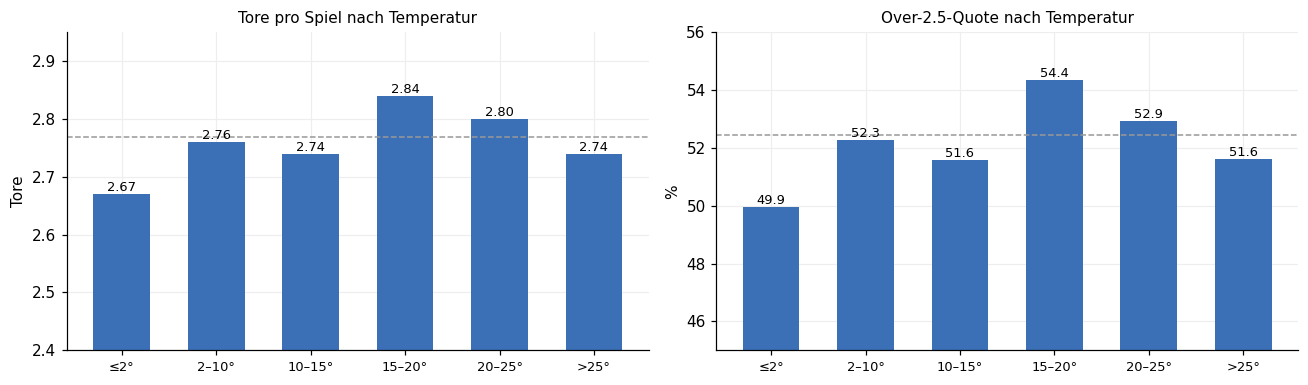

,Koeffizient,p-Wert,Effekt %,signifikant (5 %)
cold,-0.0764,0.0003,-7.35,✔
hot,0.0074,0.6958,0.74,


,Koeffizient,p-Wert,Effekt %,signifikant (5 %)
w_temp,0.0072,0.0003,0.72,✔
I(w_temp ** 2),-0.0002,0.0232,-0.02,✔


In [5]:
T_BINS, T_LAB = [-30, 2, 10, 15, 20, 25, 45], ['≤2°', '2–10°', '10–15°', '15–20°', '20–25°', '>25°']
t = binned('w_temp', T_BINS, T_LAB); display(t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bar(ax[0], t['Tore'], 'Tore pro Spiel nach Temperatur', 'Tore', df.goals.mean(), ylim=(2.4, 2.95))
bar(ax[1], t['Over 2.5 %'], 'Over-2.5-Quote nach Temperatur', '%', df.o25.mean()*100, '{:.1f}', (45, 56))
plt.tight_layout(); plt.show()
df['cold'] = (df.w_temp <= 2).astype(int); df['hot'] = (df.w_temp > 25).astype(int)
display(fit('goals', 'cold + hot', 'poisson'))
display(fit('goals', 'w_temp + I(w_temp**2)', 'poisson'))

**Antwort F1 – Ja, aber nur bei Kälte deutlich.**
- Bei **≤ 2 °C** fallen etwa **7 % weniger Tore** (2,67 statt 2,77 pro Spiel; p < 0,001). Die Over-2.5-Quote sinkt auf knapp 50 %.
- Insgesamt bildet die Temperatur ein **umgekehrtes U**: Die meisten Tore fallen bei 15–20 °C (2,84; Over 2.5 bei 54 %). Bei Hitze über 25 °C sind es wieder etwas weniger. Hitze allein ist aber nicht signifikant (p = 0,70).
- Der quadratische Term ist signifikant (p = 0,02). Der Zusammenhang ist also nicht linear.

### F2 · Fallen bei Regen mehr oder weniger Tore?

Chi²-Test 1X2 ~ w_precip_2h: p = 0.859


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt
w_precip_2h,,,,,,
trocken,16611,44.15,25.06,2.75,52.12,2.79
"0–0,5 mm",2808,43.38,25.96,2.83,52.92,2.84
"0,5–2 mm",1508,44.96,24.87,2.83,54.97,2.79
>2 mm,662,45.62,25.38,2.88,53.17,2.83


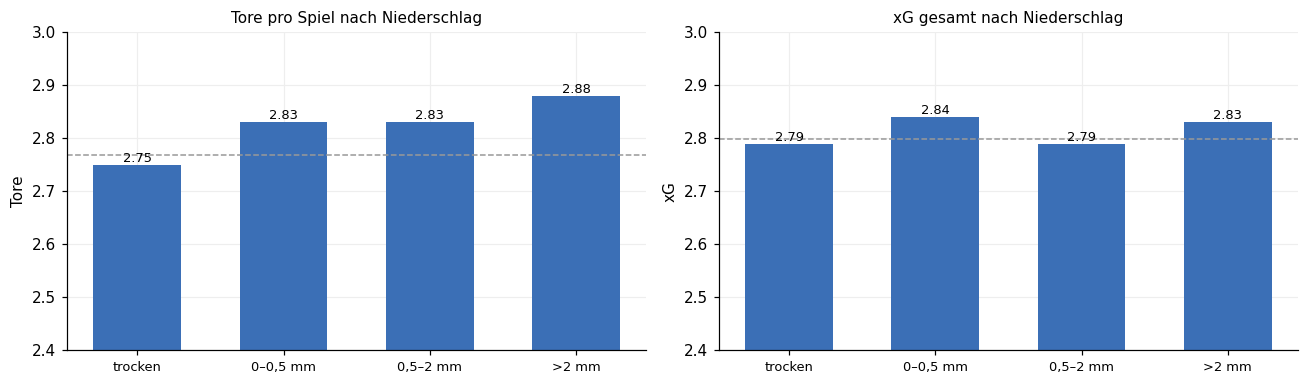

Tore:


,Koeffizient,p-Wert,Effekt %,signifikant (5 %)
rain,0.0277,0.0392,2.81,✔


xG gesamt (Chancenqualität):


,Koeffizient,p-Wert,signifikant (5 %)
rain,-0.0041,0.8692,


In [6]:
P_BINS, P_LAB = [-1, 0, 0.5, 2, 100], ['trocken', '0–0,5 mm', '0,5–2 mm', '>2 mm']
t = binned('w_precip_2h', P_BINS, P_LAB); display(t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bar(ax[0], t['Tore'], 'Tore pro Spiel nach Niederschlag', 'Tore', df.goals.mean(), ylim=(2.4, 3.0))
bar(ax[1], t['xG gesamt'], 'xG gesamt nach Niederschlag', 'xG', df.xg_tot.mean(), ylim=(2.4, 3.0))
plt.tight_layout(); plt.show()
print('Tore:'); display(fit('goals', 'rain', 'poisson'))
print('xG gesamt (Chancenqualität):'); display(fit('xg_tot', 'rain'))

**Antwort F2 – Bei Regen fallen leicht mehr Tore, aber nicht wegen besserer Chancen.**
- Bei mehr als 0,5 mm Regen in 2 Stunden steigt die Torzahl um etwa **+2,8 %** (p = 0,04). Bei mehr als 2 mm sind es im Schnitt 2,88 Tore pro Spiel.
- Das **xG ändert sich dagegen nicht** (p = 0,87). Die Teams erspielen also nicht mehr oder bessere Chancen, es werden nur mehr davon verwertet.
- Eine naheliegende, aber nicht belegte Erklärung: Fehler von Torwart und Abwehr auf nassem Rasen. Der Effekt ist knapp signifikant und sollte mit Vorsicht behandelt werden.

### F3 · Senkt starker Wind die Torzahl und die Chancenqualität?

Chi²-Test 1X2 ~ w_wind: p = 0.291


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt
w_wind,,,,,,
≤10,10073,44.27,25.58,2.78,52.45,2.79
10–20,8268,44.33,24.44,2.78,52.81,2.82
20–30,2620,43.93,25.31,2.70,51.83,2.76
>30 km/h,628,40.92,27.55,2.72,50.64,2.78


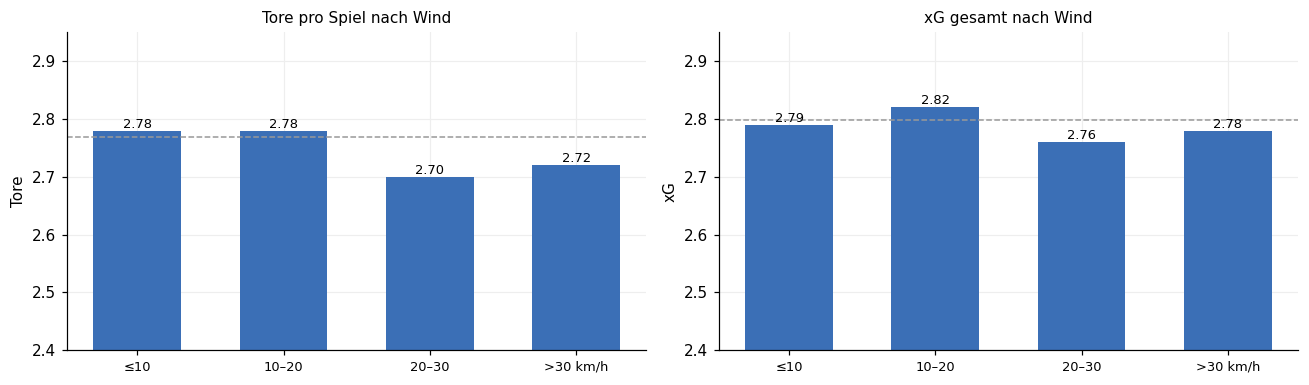

Tore (Effekt je +10 km/h):


,Koeffizient,p-Wert,Effekt %,signifikant (5 %)
wind10,-0.0202,0.0006,-2.0,✔


xG gesamt (je +10 km/h):


,Koeffizient,p-Wert,signifikant (5 %)
wind10,-0.0322,0.0023,✔


In [7]:
W_BINS, W_LAB = [-1, 10, 20, 30, 200], ['≤10', '10–20', '20–30', '>30 km/h']
t = binned('w_wind', W_BINS, W_LAB); display(t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bar(ax[0], t['Tore'], 'Tore pro Spiel nach Wind', 'Tore', df.goals.mean(), ylim=(2.4, 2.95))
bar(ax[1], t['xG gesamt'], 'xG gesamt nach Wind', 'xG', df.xg_tot.mean(), ylim=(2.4, 2.95))
plt.tight_layout(); plt.show()
df['wind10'] = df.w_wind / 10
print('Tore (Effekt je +10 km/h):'); display(fit('goals', 'wind10', 'poisson'))
print('xG gesamt (je +10 km/h):'); display(fit('xg_tot', 'wind10'))

**Antwort F3 – Ja. Wind ist der robusteste Wettereffekt.**
- Pro **+10 km/h** Wind fallen etwa **2 % weniger Tore** (p < 0,001).
- Auch das **xG insgesamt** sinkt um 0,03 je 10 km/h (p = 0,002). Wind verschlechtert also tatsächlich die Chancenqualität, vermutlich weil präzise Flanken und lange Bälle schwieriger werden.
- Bei Sturm über 30 km/h (628 Spiele) liegt die Over-2.5-Quote bei 50,6 % statt 52,5 %.

### F4 · Beeinflusst das Wetter den Sieger (1X2)?

Heimsieg (Logit):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
w_temp,0.0056,0.4352,1.006,
I(w_temp ** 2),-0.0003,0.2704,1.000,
w_wind,-0.0011,0.6225,0.999,
rain,0.0416,0.4122,1.042,


Remis (Logit):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
w_temp,-0.0095,0.2073,0.991,
I(w_temp ** 2),0.0003,0.2096,1.000,
w_wind,0.0017,0.4460,1.002,
rain,-0.0070,0.8964,0.993,


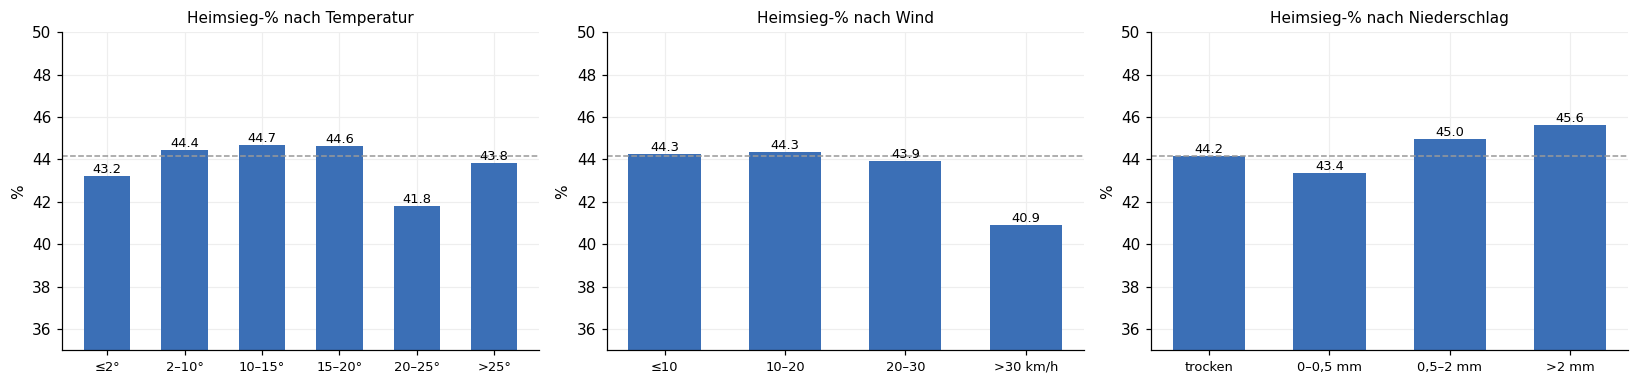

In [8]:
terms = 'w_temp + I(w_temp**2) + w_wind + rain'
print('Heimsieg (Logit):'); display(fit('hwin', terms, 'logit'))
print('Remis (Logit):');    display(fit('draw', terms, 'logit'))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, (col, b, l, ttl) in zip(ax, [('w_temp', T_BINS, T_LAB, 'Temperatur'), ('w_wind', W_BINS, W_LAB, 'Wind'),
                                     ('w_precip_2h', P_BINS, P_LAB, 'Niederschlag')]):
    s = df.groupby(pd.cut(df[col], b, labels=l), observed=True).hwin.mean()*100
    bar(a_, s, f'Heimsieg-% nach {ttl}', '%', df.hwin.mean()*100, '{:.1f}', (35, 50))
plt.tight_layout(); plt.show()

**Antwort F4 – Nein. Das Wetter bestimmt nicht, wer gewinnt.**
- Weder Temperatur noch Wind noch Regen haben einen signifikanten Einfluss auf die Wahrscheinlichkeit eines Heimsiegs oder eines Remis. Alle p-Werte liegen über 0,2, die Odds Ratios bei etwa 1,00.
- Die Ausnahme, die man auf den ersten Blick sieht, ist Sturm über 30 km/h: 40,9 % Heimsiege und 27,6 % Remis. Das sind aber nur 628 Spiele, und der Effekt ist nicht signifikant.
- **Interpretation:** Wetter betrifft *beide* Teams gleich. Es beeinflusst eher das **Torniveau** (F1–F3) als die **Kräfteverhältnisse**.

### F5 · Bestimmt die Reisedistanz die Heimstärke einer Mannschaft?

Chi²-Test 1X2 ~ travel_km: p = 0.391


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt,Auswärtspunkte
travel_km,,,,,,,
≤150,4382,42.86,25.17,2.77,52.37,2.80,1.211
150–300,5840,43.92,25.10,2.82,53.29,2.87,1.180
300–500,6144,44.92,24.76,2.80,53.73,2.82,1.157
500–800,4077,44.67,25.73,2.67,49.84,2.68,1.145
>800 km,1146,44.33,25.74,2.73,51.05,2.73,1.155


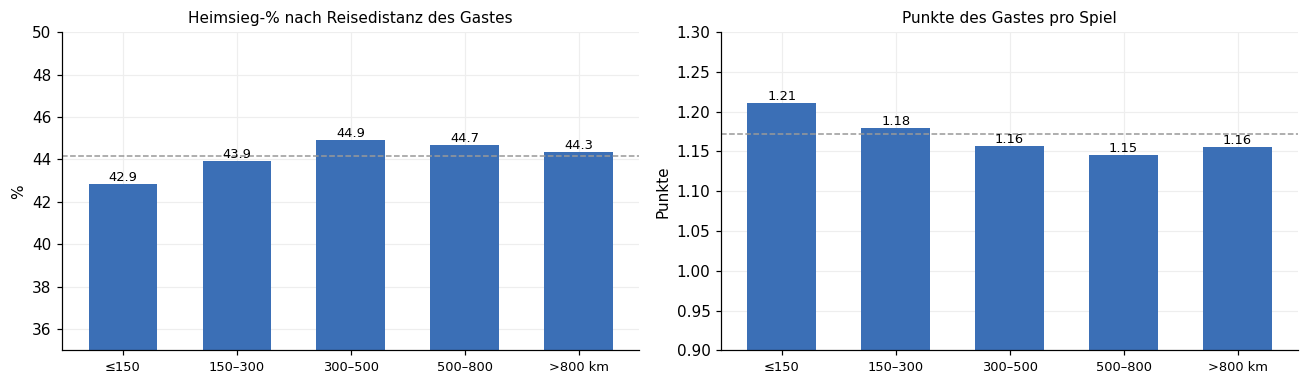

Heimsieg je +100 km (Logit, alle Spiele):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
trav100,0.0069,0.281,1.007,


… ohne Las Palmas (Kanaren, Extremdistanzen):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
trav100,0.0065,0.3938,1.006,


Wirkt Distanz unter der Woche (Di–Do) stärker?


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
trav100,0.0074,0.2636,1.007,
midweek,0.0827,0.3030,1.086,
trav100:midweek,-0.0044,0.8125,0.996,


Effekt je Liga (Koeffizient je 100 km, p-Wert):
  Bundesliga  -0.001  p = 0.978
  EPL         +0.049  p = 0.093
  La Liga     +0.006  p = 0.530
  Ligue 1     -0.015  p = 0.286
  Serie A     +0.024  p = 0.093


In [9]:
D_BINS, D_LAB = [-1, 150, 300, 500, 800, 3000], ['≤150', '150–300', '300–500', '500–800', '>800 km']
t = binned('travel_km', D_BINS, D_LAB)
t['Auswärtspunkte'] = df.groupby(pd.cut(df.travel_km, D_BINS, labels=D_LAB), observed=True).away_points.mean().round(3)
display(t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
bar(ax[0], t['Heimsieg %'], 'Heimsieg-% nach Reisedistanz des Gastes', '%', df.hwin.mean()*100, '{:.1f}', (35, 50))
bar(ax[1], t['Auswärtspunkte'], 'Punkte des Gastes pro Spiel', 'Punkte', df.away_points.mean(), ylim=(0.9, 1.3))
plt.tight_layout(); plt.show()
print('Heimsieg je +100 km (Logit, alle Spiele):'); display(fit('hwin', 'trav100', 'logit'))
no_lp = df[(df.home_team != 'Las Palmas') & (df.away_team != 'Las Palmas')]
print('… ohne Las Palmas (Kanaren, Extremdistanzen):'); display(fit('hwin', 'trav100', 'logit', no_lp))
df['midweek'] = df.date.dt.dayofweek.isin([1, 2, 3]).astype(int)
print('Wirkt Distanz unter der Woche (Di–Do) stärker?'); display(fit('hwin', 'trav100 * midweek', 'logit'))
print('Effekt je Liga (Koeffizient je 100 km, p-Wert):')
for lg, g in df.groupby('league'):
    m = smf.logit('hwin ~ trav100 + strdiff + ghost', g).fit(disp=0)
    print(f'  {lg:<11} {m.params.trav100:+.3f}  p = {m.pvalues.trav100:.3f}')

**Antwort F5 – Nein. Die Distanz bestimmt die Heimstärke praktisch nicht.**
- Deskriptiv steigt die Heimsiegquote von 42,9 % (Gast reist höchstens 150 km) auf etwa 44,5 % (über 300 km). Die Auswärtspunkte sinken leicht von 1,21 auf 1,15.
- Mit Kontrollen für Teamstärke und Liga ist der Effekt aber **nicht signifikant**: Pro 100 km steigt die Odds Ratio nur auf 1,007 (p = 0,28). Das gilt auch ohne Las Palmas und bei Spielen unter der Woche, wo man Müdigkeit erwarten würde (Interaktion p = 0,81).
- In der EPL und der Serie A gibt es schwache Hinweise (p ≈ 0,09), in den anderen Ligen nichts.
- **Gründe:** Die Distanzen in den Top-5-Ligen sind klein (Median etwa 310 km), und die Teams reisen per Charterflug. Der Heimvorteil kommt vor allem vom **Publikum** (siehe Geisterspiele unten).

### F6 · Verändert eine weite Anreise den Spielstil des Gastes?

Abweichung gegenüber Gästen mit ≤150 km Anreise (bei gleicher Teamstärke/Liga):


,PPDA Gast (hoch = weniger Pressing),xG Gast,xG Heimteam,Deep Completions Gast
b_150-300,-0.0485 (p=0.714),0.0055 (p=0.698),0.0531 (p=0.001),-0.0473 (p=0.478)
c_300-500,0.4418 (p=0.001),-0.0113 (p=0.447),0.0346 (p=0.038),0.018 (p=0.796)
d_500-800,0.3152 (p=0.046),-0.038 (p=0.026),-0.0091 (p=0.634),-0.0381 (p=0.632)
e_>800,0.285 (p=0.215),-0.033 (p=0.185),0.05 (p=0.073),-0.0478 (p=0.68)


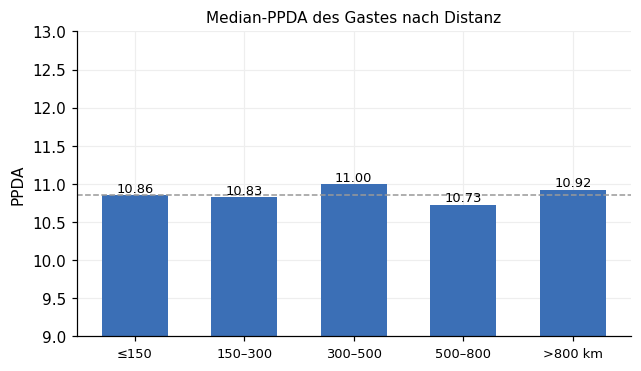

In [10]:
df['tbin'] = pd.cut(df.travel_km, D_BINS, labels=['a_≤150', 'b_150-300', 'c_300-500', 'd_500-800', 'e_>800'])
res = {}
for y, lab in [('away_ppda', 'PPDA Gast (hoch = weniger Pressing)'), ('away_xg', 'xG Gast'),
               ('home_xg', 'xG Heimteam'), ('away_deep_completions', 'Deep Completions Gast')]:
    r = fit(y, 'C(tbin)'); r.index = [i.split('T.')[1][:-1] for i in r.index]
    res[lab] = r['Koeffizient'].astype(str) + ' (p=' + r['p-Wert'].round(3).astype(str) + ')'
print('Abweichung gegenüber Gästen mit ≤150 km Anreise (bei gleicher Teamstärke/Liga):')
display(pd.DataFrame(res))
s = df.groupby(pd.cut(df.travel_km, D_BINS, labels=D_LAB), observed=True).away_ppda.median()
fig, ax = plt.subplots(figsize=(6.5, 3.6)); bar(ax, s, 'Median-PPDA des Gastes nach Distanz', 'PPDA', df.away_ppda.median(), ylim=(9, 13)); plt.show()

**Antwort F6 – Leicht, ja. Gäste mit weiter Anreise spielen etwas passiver.**
- Ab etwa 300 km steigt der **PPDA-Wert des Gastes um 0,3–0,4** (p = 0,001 bzw. 0,046). Der Gast presst also weniger.
- Bei 500–800 km erzielt der Gast etwa **0,04 xG weniger** (p = 0,026). Das Heimteam kommt bei mittleren Distanzen auf etwas mehr xG.
- Die Effekte sind klein und folgen keinem sauberen Trend nach dem Muster „je weiter, desto stärker“. Weil mehrere Tests gerechnet wurden, kann ein Teil davon Zufall sein. Inhaltlich passt das Bild aber zusammen: **Die Reise verändert den Spielstil ein wenig, aber nicht das Ergebnis.**

### F7 · Sind Derbys anders?

In [11]:
g = df.groupby('is_derby')
t = pd.DataFrame({'n': g.size(), 'Heimsieg %': g.hwin.mean()*100, 'Remis %': g.draw.mean()*100,
                  'Auswärtssieg %': (g.res.apply(lambda s: (s == 'A').mean()))*100,
                  'Tore': g.goals.mean(), 'xG gesamt': g.xg_tot.mean()}).round(2).rename(index={0: 'kein Derby', 1: 'Derby (<30 km)'})
display(t)
print('Chi²-Test 1X2 ~ Derby: p = %.3f' % chi2_contingency(pd.crosstab(df.is_derby, df.res))[1])
print('Heimsieg:'); display(fit('hwin', 'is_derby', 'logit'))
print('Tore:');     display(fit('goals', 'is_derby', 'poisson'))
print('Häufigste Derby-Paarungen:')
display(df[df.is_derby == 1].groupby(['home_team', 'away_team']).size().sort_values(ascending=False).head(8))

,n,Heimsieg %,Remis %,Auswärtssieg %,Tore,xG gesamt
is_derby,,,,,,
kein Derby,20647,44.19,25.17,30.64,2.77,2.8
Derby (<30 km),942,43.42,25.16,31.42,2.67,2.8


Chi²-Test 1X2 ~ Derby: p = 0.861
Heimsieg:


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
is_derby,-0.0481,0.5193,0.953,


Tore:


,Koeffizient,p-Wert,Effekt %,signifikant (5 %)
is_derby,-0.0361,0.0804,-3.55,


Häufigste Derby-Paarungen:


home_team        away_team     
AC Milan         Inter             12
Arsenal          Chelsea           12
Atletico Madrid  Real Madrid       12
Arsenal          Crystal Palace    12
                 West Ham          12
                 Tottenham         12
Liverpool        Everton           12
Inter            AC Milan          12
dtype: int64

**Antwort F7 – Beim Ergebnis nein, bei den Toren tendenziell schon.**
- Die Verteilung von Heimsieg, Remis und Auswärtssieg ist bei Derbys praktisch identisch (43,4 % / 25,2 % / 31,4 %; p = 0,86). Der Heimvorteil schrumpft also nicht messbar, obwohl der Gast kaum reisen muss und oft viele eigene Fans dabei hat.
- In Derbys fallen etwa **3,5 % weniger Tore** (2,67 gegenüber 2,77). Das ist knapp nicht signifikant (p = 0,08), passt aber zum Bild „enger, vorsichtiger“. Das xG ist gleich, der Unterschied liegt also eher in der Chancenverwertung.

### F8 · Gibt es ein Nord-Süd-Gefälle im Heimvorteil, und leidet der Gast unter einem Klimaschock?

Chi²-Test 1X2 ~ home_lat: p = 0.007


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt
home_lat,,,,,,
<40° (Süden),2014,40.47,27.36,2.64,49.16,2.73
40–45°,6586,44.75,25.61,2.70,50.61,2.72
45–50°,5755,43.96,25.04,2.78,52.46,2.80
50–53°,5315,44.20,24.53,2.87,55.39,2.88
>53° (Norden),1919,46.43,23.50,2.83,54.14,2.87


Heimsieg ~ Breitengrad OHNE Kontrollen:
  Koeffizient +0.0002, p = 0.9485
Heimsieg ~ Breitengrad MIT Kontrollen (Liga, Teamstärke, Geisterspiele):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
home_lat,-0.0074,0.3042,0.993,


Chi²-Test 1X2 ~ w_temp_diff_away: p = 0.446


,n,Heimsieg %,Remis %,Tore,Over 2.5 %,xG gesamt
w_temp_diff_away,,,,,,
<−8,877,45.50,27.14,2.61,46.98,2.66
−8…−4,3173,45.89,23.95,2.70,51.02,2.71
−4…−1,5155,43.96,24.99,2.77,52.45,2.79
±1,3843,43.25,25.21,2.77,52.77,2.79
1…4,4773,43.93,25.41,2.80,53.22,2.86
4…8,2977,43.80,25.76,2.82,53.44,2.85
>8 °C,763,43.51,25.43,2.81,53.87,2.89


Heimsieg ~ Klimaschock (Betrag der Temperaturdifferenz):


,Koeffizient,p-Wert,Odds Ratio,signifikant (5 %)
tdabs,0.0026,0.635,1.003,


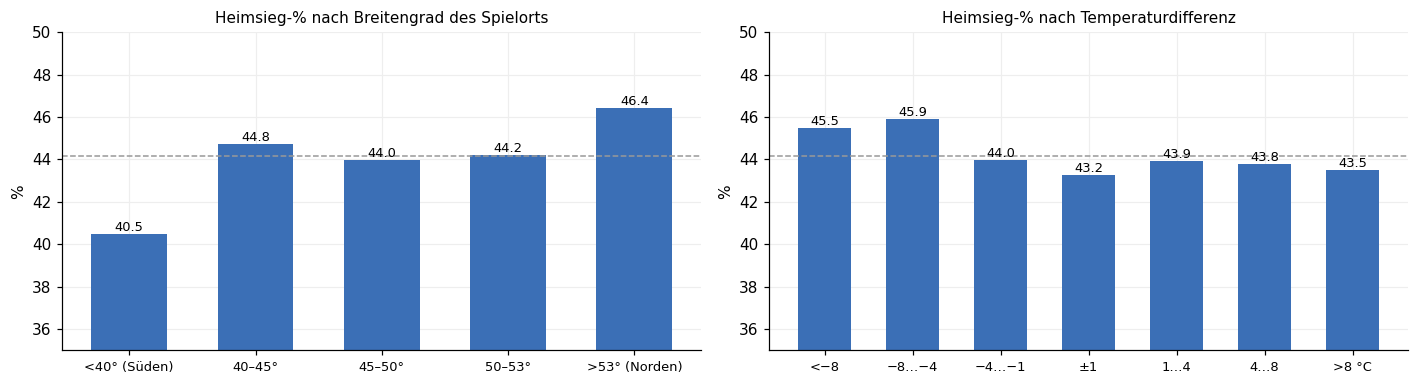

In [12]:
L_BINS, L_LAB = [0, 40, 45, 50, 53, 70], ['<40° (Süden)', '40–45°', '45–50°', '50–53°', '>53° (Norden)']
t = binned('home_lat', L_BINS, L_LAB); display(t)
print('Heimsieg ~ Breitengrad OHNE Kontrollen:')
m0 = smf.logit('hwin ~ home_lat', df).fit(disp=0); print(f'  Koeffizient {m0.params.home_lat:+.4f}, p = {m0.pvalues.home_lat:.4f}')
print('Heimsieg ~ Breitengrad MIT Kontrollen (Liga, Teamstärke, Geisterspiele):'); display(fit('hwin', 'home_lat', 'logit'))

C_BINS, C_LAB = [-50, -8, -4, -1, 1, 4, 8, 50], ['<−8', '−8…−4', '−4…−1', '±1', '1…4', '4…8', '>8 °C']
t2 = binned('w_temp_diff_away', C_BINS, C_LAB); display(t2)
df['tdabs'] = df.w_temp_diff_away.abs()
print('Heimsieg ~ Klimaschock (Betrag der Temperaturdifferenz):'); display(fit('hwin', 'tdabs', 'logit'))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
bar(ax[0], t['Heimsieg %'], 'Heimsieg-% nach Breitengrad des Spielorts', '%', df.hwin.mean()*100, '{:.1f}', (35, 50))
bar(ax[1], t2['Heimsieg %'], 'Heimsieg-% nach Temperaturdifferenz', '%', df.hwin.mean()*100, '{:.1f}', (35, 50))
plt.tight_layout(); plt.show()

**Antwort F8 – Ein Nord-Süd-Gefälle gibt es nur scheinbar, einen Klimaschock gar nicht.**
- Deskriptiv sieht es nach einem Gefälle aus: Im Süden (unter 40°, vor allem Andalusien und Kanaren) gewinnen Heimteams nur 40,5 %, im Norden (über 53°) 46,4 %. Der Chi²-Test ist signifikant (p = 0,007).
- **Mit Kontrollen** für Liga und Teamstärke **verschwindet der Effekt** (p = 0,30). Hinter dem Muster stecken die Zusammensetzung der Ligen und schwache Teams im Süden, zum Beispiel Las Palmas, Almería und Cádiz, nicht die Geografie. Ein Lehrbeispiel für eine **Scheinkorrelation**.
- Interessant ist auch: Nach Norden steigt die Torzahl (2,64 auf 2,87). Das ist vor allem ein **Ligaeffekt**, denn in der Bundesliga und der EPL fallen mehr Tore als in La Liga.
- **Klimaschock:** Der Betrag der Temperaturdifferenz zwischen dem Heimatort des Gastes und dem Spielort hat keinen Effekt auf den Heimsieg (p = 0,64). Ist es am Spielort deutlich kälter, fallen weniger Tore. Das ist aber derselbe Kälteeffekt wie in F1.

---
## Teil B – Understat-Daten im Zeitverlauf

Für Teil B wird eine **Team-Spiel-Tabelle** gebaut: jedes Spiel zweimal, einmal aus Sicht des Heimteams und einmal aus Sicht des Gastes. Damit lassen sich Kennzahlen pro Team und Saison berechnen.

In [13]:
def team_view(d):
    cols = ['goals', 'xg', 'points', 'expected_points', 'ppda', 'deep_completions']
    h = d[['season_id', 'date', 'league', 'home_team'] + [f'home_{c}' for c in cols] + ['away_goals', 'away_xg']].copy()
    h.columns = ['season', 'date', 'league', 'team'] + cols + ['ga', 'xga']; h['venue'] = 'H'
    a = d[['season_id', 'date', 'league', 'away_team'] + [f'away_{c}' for c in cols] + ['home_goals', 'home_xg']].copy()
    a.columns = h.columns[:-1]; a['venue'] = 'A'
    return pd.concat([h, a]).sort_values('date').reset_index(drop=True)
tv = team_view(df)
SEASONS = sorted(df.season_id.unique()); SLAB = [f'{s%100:02d}/{(s+1)%100:02d}' for s in SEASONS]
def trend(series):
    r = stats.linregress(np.arange(len(series)), series.values)
    return f'Trend {r.slope:+.4f} pro Saison, p = {r.pvalue:.3f}'
print(tv.shape)

(43178, 13)


### F9 · Wie hat sich der Heimvorteil von 2014 bis 2025 entwickelt?

,14/15,15/16,16/17,17/18,18/19,19/20,20/21,21/22,22/23,23/24,24/25,25/26
heimsieg,45.000,44.400,48.700,45.300,44.700,44.100,39.900,42.800,45.700,43.100,42.000,44.000
remis,26.000,25.900,23.100,24.500,25.800,24.300,25.500,25.800,24.300,26.400,25.000,25.500
auswaertssieg,29.100,29.700,28.300,30.200,29.400,31.500,34.700,31.400,30.000,30.500,33.000,30.500
pkt_diff,0.476,0.439,0.613,0.455,0.460,0.377,0.156,0.342,0.472,0.378,0.271,0.404
xg_diff,0.375,0.345,0.367,0.376,0.354,0.274,0.172,0.284,0.342,0.417,0.277,0.378


Heimsieg-% alle Saisons:           Trend -0.2764 pro Saison, p = 0.132
Heimsieg-% ohne Corona-Saisons:    Trend -0.3262 pro Saison, p = 0.116


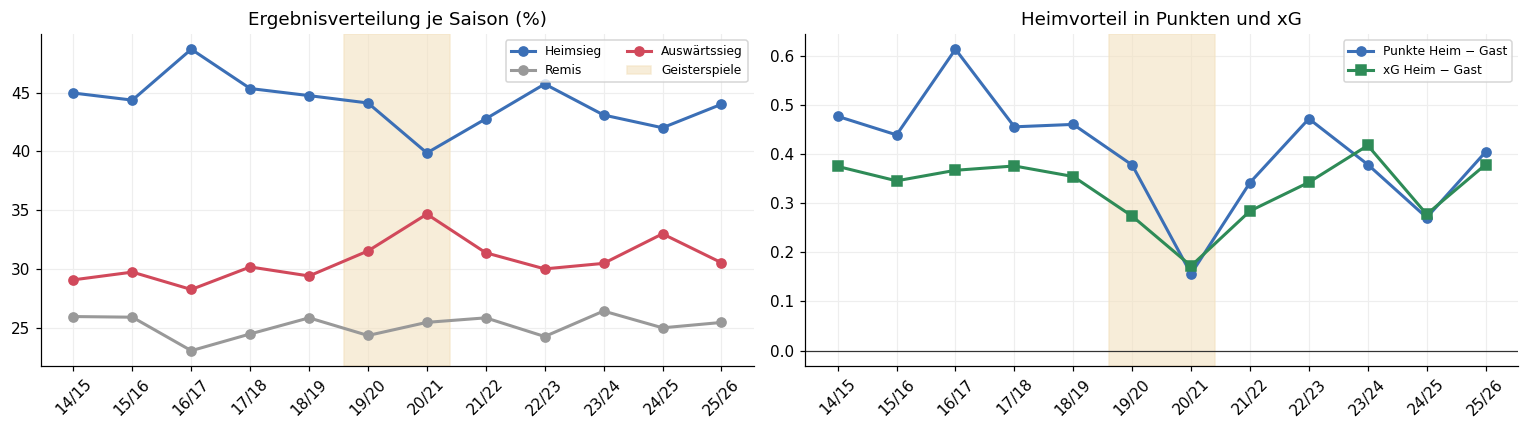

,n,heimsieg,xg_diff
phase,,,
1 vor Corona,10447,45.5,0.357
2 Geisterspiele,2234,40.2,0.166
3 nach Corona,8908,43.5,0.339


Heimsieg-% je Liga und Phase:


phase,1 vor Corona,2 Geisterspiele,3 nach Corona
league,,,
Bundesliga,45.8,39.9,44.1
EPL,45.7,39.6,44.2
La Liga,46.6,41.4,45.7
Ligue 1,45.8,37.4,43.4
Serie A,43.8,41.7,40.4


In [14]:
s = df.groupby('season_id').agg(heimsieg=('hwin', 'mean'), remis=('draw', 'mean'),
                                auswaertssieg=('res', lambda r: (r == 'A').mean()),
                                pkt_heim=('home_points', 'mean'), pkt_gast=('away_points', 'mean'),
                                xg_heim=('home_xg', 'mean'), xg_gast=('away_xg', 'mean'))
s['pkt_diff'] = s.pkt_heim - s.pkt_gast; s['xg_diff'] = s.xg_heim - s.xg_gast
s.index = SLAB
display((s[['heimsieg', 'remis', 'auswaertssieg']] * 100).round(1).join(s[['pkt_diff', 'xg_diff']].round(3)).T)
print('Heimsieg-% alle Saisons:          ', trend(s.heimsieg * 100))
ohne = s.drop(['19/20', '20/21'])
print('Heimsieg-% ohne Corona-Saisons:   ', trend(ohne.heimsieg * 100))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for col, c, lab in [('heimsieg', BLUE, 'Heimsieg'), ('remis', GREY, 'Remis'), ('auswaertssieg', '#d1495b', 'Auswärtssieg')]:
    ax[0].plot(SLAB, s[col] * 100, marker='o', color=c, lw=2, label=lab)
ax[0].axvspan(4.6, 6.4, color='#f3e2c0', alpha=0.6, label='Geisterspiele'); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title('Ergebnisverteilung je Saison (%)'); ax[0].tick_params(axis='x', rotation=45)
ax[1].plot(SLAB, s.pkt_diff, marker='o', color=BLUE, lw=2, label='Punkte Heim − Gast')
ax[1].plot(SLAB, s.xg_diff, marker='s', color='#2e8b57', lw=2, label='xG Heim − Gast')
ax[1].axvspan(4.6, 6.4, color='#f3e2c0', alpha=0.6); ax[1].axhline(0, color='#333', lw=0.8)
ax[1].legend(fontsize=8); ax[1].set_title('Heimvorteil in Punkten und xG'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# Monatsgenau: Geisterspiele vs. davor/danach
df['phase'] = np.select([df.date < '2020-03-15', df.date <= '2021-06-30'], ['1 vor Corona', '2 Geisterspiele'], '3 nach Corona')
display(df.groupby('phase').agg(n=('hwin', 'size'), heimsieg=('hwin', 'mean'), xg_diff=('home_xg', 'mean'))
          .assign(heimsieg=lambda x: (x.heimsieg * 100).round(1),
                  xg_diff=df.groupby('phase').apply(lambda g: (g.home_xg - g.away_xg).mean()).round(3)))
print('Heimsieg-% je Liga und Phase:')
display((df.pivot_table(index='league', columns='phase', values='hwin') * 100).round(1))

**Antwort F9 – Der Heimvorteil ist erstaunlich stabil. Der einzige echte Einbruch kam durch die Geisterspiele.**
- Vor Corona lag die Heimsiegquote bei **45,5 %**. In den Geisterspielen (03/2020–06/2021) fiel sie auf **40,2 %**, danach stieg sie wieder auf **43,5 %**.
- Auch die **xG-Differenz** zwischen Heim- und Gastteam halbierte sich ohne Publikum (0,36 → 0,17) und kam danach fast vollständig zurück (0,34). Die Heimteams haben ohne Fans also nicht nur seltener gewonnen, sondern **auch schlechter gespielt**.
- Über die zwölf Saisons gibt es einen leicht fallenden Trend (−0,3 Prozentpunkte pro Saison). Er ist aber **nicht signifikant** (p = 0,12, auch ohne die Corona-Saisons).
- Fast alle Ligen liegen nach Corona noch 1–2 Prozentpunkte unter ihrem Niveau vor Corona. Auffällig ist die **Serie A**: Sie hatte schon vorher den schwächsten Heimvorteil und liegt nach Corona mit **40,4 %** sogar unter ihrem Wert aus den Geisterspielen (41,7 %).

### F10 · Fallen heute mehr Tore als 2014, und steigt die Chancenqualität mit?

,14/15,15/16,16/17,17/18,18/19,19/20,20/21,21/22,22/23,23/24,24/25,25/26
tore,2.628,2.669,2.835,2.709,2.749,2.792,2.801,2.811,2.766,2.885,2.827,2.765
xg,2.546,2.609,2.624,2.631,2.809,2.807,2.746,2.825,2.866,3.054,3.049,3.044
o25,0.486,0.502,0.544,0.515,0.522,0.546,0.525,0.524,0.522,0.549,0.534,0.530
tore_minus_xg,0.082,0.060,0.211,0.078,-0.060,-0.015,0.055,-0.014,-0.100,-0.169,-0.221,-0.279


Tore/Spiel:   Trend +0.0131 pro Saison, p = 0.022
xG/Spiel:     Trend +0.0476 pro Saison, p = 0.000
Tore − xG:    Trend -0.0344 pro Saison, p = 0.000


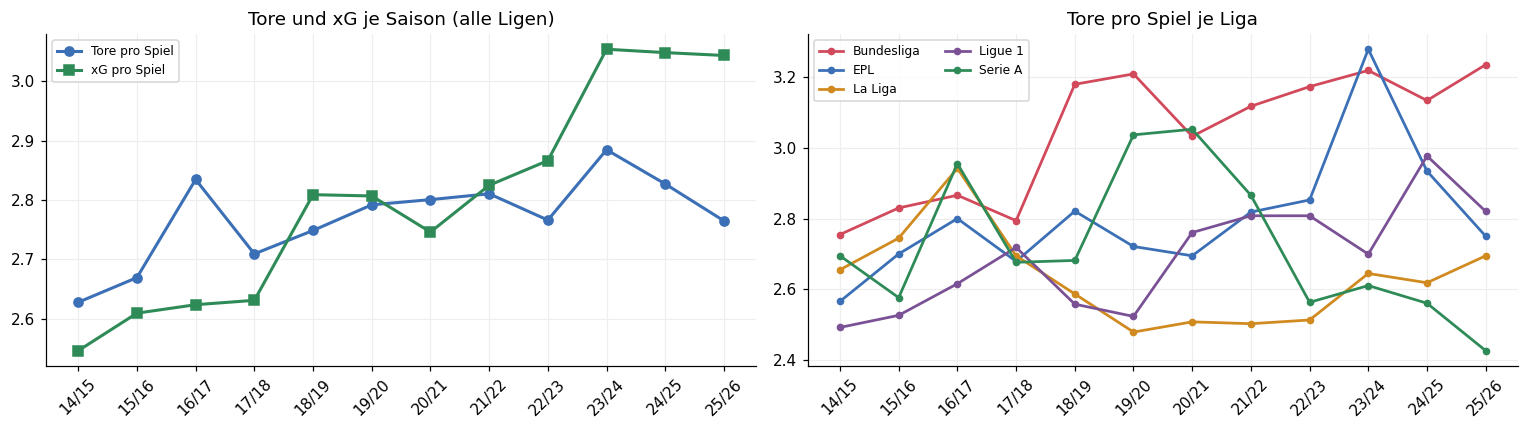

Trend je Liga (Tore/Spiel):
  Bundesliga  Trend +0.0420 pro Saison, p = 0.001
  EPL         Trend +0.0291 pro Saison, p = 0.044
  La Liga     Trend -0.0137 pro Saison, p = 0.228
  Ligue 1     Trend +0.0339 pro Saison, p = 0.001
  Serie A     Trend -0.0192 pro Saison, p = 0.281


In [15]:
s = df.groupby('season_id').agg(tore=('goals', 'mean'), xg=('xg_tot', 'mean'), o25=('o25', 'mean'))
s['tore_minus_xg'] = s.tore - s.xg; s.index = SLAB
display(s.round(3).T)
print('Tore/Spiel:  ', trend(s.tore)); print('xG/Spiel:    ', trend(s.xg)); print('Tore − xG:   ', trend(s.tore_minus_xg))
lt = df.pivot_table(index='season_id', columns='league', values='goals'); lt.index = SLAB

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(SLAB, s.tore, marker='o', color=BLUE, lw=2, label='Tore pro Spiel')
ax[0].plot(SLAB, s.xg, marker='s', color='#2e8b57', lw=2, label='xG pro Spiel')
ax[0].legend(fontsize=8); ax[0].set_title('Tore und xG je Saison (alle Ligen)'); ax[0].tick_params(axis='x', rotation=45)
for l in lt.columns:
    ax[1].plot(SLAB, lt[l], marker='o', ms=4, lw=1.8, color=LCOL[l], label=l)
ax[1].legend(fontsize=8, ncol=2); ax[1].set_title('Tore pro Spiel je Liga'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
print('Trend je Liga (Tore/Spiel):')
for l in lt.columns: print(f'  {l:<11}', trend(lt[l]))

**Antwort F10 – Es fallen leicht mehr Tore, und das xG steigt sogar deutlich stärker.**
- Die Tore pro Spiel steigen von 2,63 (14/15) auf etwa 2,8 (seit 19/20). Das ist ein signifikanter Trend von +0,013 pro Saison (p = 0,02). Die Over-2.5-Quote steigt von 49 % auf rund 53 %.
- Das **xG pro Spiel** wächst viel schneller: von 2,55 auf 3,04 (+0,048 pro Saison, p < 0,001).
- Deshalb kippt die **Differenz Tore − xG**: Bis 2017 lagen die Tore über dem xG (+0,08), seit 2022/23 deutlich darunter (−0,28 im Jahr 2025/26). Das ist sehr wahrscheinlich **kein echtes „schlechteres Abschließen“**. Vermutlich hat Understat sein xG-Modell über die Jahre neu kalibriert oder neue Schussarten aufgenommen.
- Nach Ligen: Mehr Tore gibt es vor allem in der **Bundesliga** (+0,042 pro Saison), der **Ligue 1** und der **EPL**. In La Liga und der Serie A gibt es keinen Trend.

### F11 · Hat sich das Pressing verändert, und gewinnen Pressing-Teams häufiger?

,14/15,15/16,16/17,17/18,18/19,19/20,20/21,21/22,22/23,23/24,24/25,25/26
league,,,,,,,,,,,,
Bundesliga,8.13,8.41,8.54,9.83,11.16,10.84,11.29,10.87,11.09,12.86,12.94,12.84
EPL,9.75,9.35,9.93,10.50,11.21,10.61,11.62,11.17,11.52,11.57,11.45,11.23
La Liga,7.79,7.94,8.60,9.07,9.42,9.27,9.87,9.67,10.11,10.76,11.09,10.78
Ligue 1,8.65,9.21,9.89,10.11,10.25,10.76,11.43,11.87,10.89,11.44,11.26,11.53
Serie A,8.85,8.35,9.77,10.55,10.53,10.38,10.80,10.21,11.47,12.10,11.78,11.58
Alle,8.58,8.68,9.37,10.00,10.44,10.28,10.96,10.74,11.02,11.72,11.64,11.50


Median-PPDA (alle Ligen): Trend +0.2869 pro Saison, p = 0.000


,n,ppda,punkte_pro_spiel,xg_diff
Pressing-Quartil,,,,
Q1 viel Pressing,293,8.57,1.67,0.42
Q2,292,10.72,1.41,0.08
Q3,292,12.63,1.31,-0.12
Q4 wenig Pressing,293,15.66,1.12,-0.38


Korrelation PPDA ↔ Punkte/Spiel: r = -0.45, p = 3e-58
Punkte ~ PPDA + xG-Diff: PPDA-Koeffizient +0.0030 (p = 0.212), xG-Diff +0.696 (p < 0,001)
Spielebene: Das Team mit mehr Pressing gewinnt 40.6 % und verliert 34.2 %


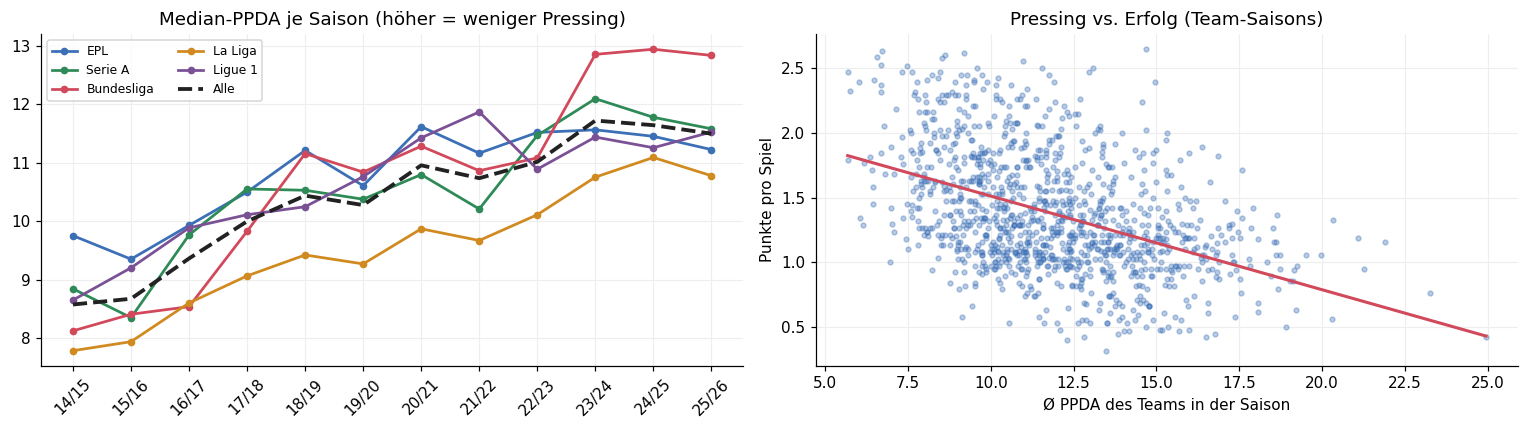

In [16]:
p = tv.dropna(subset=['ppda']).pivot_table(index='season', columns='league', values='ppda', aggfunc='median'); p.index = SLAB
p['Alle'] = tv.dropna(subset=['ppda']).groupby('season').ppda.median().values
display(p.round(2).T)
print('Median-PPDA (alle Ligen):', trend(p['Alle']))

# Team-Saison-Ebene
ts = tv.groupby(['season', 'league', 'team']).agg(ppda=('ppda', 'mean'), pkt=('points', 'mean'),
                                                  xgd=('xg', 'mean'), xga=('xga', 'mean')).reset_index()
ts['xgd'] = ts.xgd - ts.xga
ts['Pressing-Quartil'] = pd.qcut(ts.ppda, 4, labels=['Q1 viel Pressing', 'Q2', 'Q3', 'Q4 wenig Pressing'])
q4 = ts.groupby('Pressing-Quartil', observed=True).agg(n=('pkt', 'size'), ppda=('ppda', 'mean'), punkte_pro_spiel=('pkt', 'mean'), xg_diff=('xgd', 'mean')).round(2)
display(q4)
r = stats.pearsonr(ts.ppda, ts.pkt); print(f'Korrelation PPDA ↔ Punkte/Spiel: r = {r[0]:.2f}, p = {r[1]:.1g}')
m = smf.ols('pkt ~ ppda + xgd + C(league)', ts).fit()
print(f'Punkte ~ PPDA + xG-Diff: PPDA-Koeffizient {m.params.ppda:+.4f} (p = {m.pvalues.ppda:.3f}), xG-Diff {m.params.xgd:+.3f} (p < 0,001)')

d = df.dropna(subset=['home_ppda', 'away_ppda']); mehr = d.home_ppda < d.away_ppda
win = ((mehr & (d.res == 'H')) | (~mehr & (d.res == 'A'))).mean(); lose = ((mehr & (d.res == 'A')) | (~mehr & (d.res == 'H'))).mean()
print(f'Spielebene: Das Team mit mehr Pressing gewinnt {win*100:.1f} % und verliert {lose*100:.1f} %')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for l in LCOL: ax[0].plot(SLAB, p[l], marker='o', ms=4, lw=1.8, color=LCOL[l], label=l)
ax[0].plot(SLAB, p['Alle'], color='#222', lw=2.5, ls='--', label='Alle'); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title('Median-PPDA je Saison (höher = weniger Pressing)'); ax[0].tick_params(axis='x', rotation=45)
ax[1].scatter(ts.ppda, ts.pkt, s=10, alpha=0.35, color=BLUE)
k = np.polyfit(ts.ppda, ts.pkt, 1); xs = np.linspace(ts.ppda.min(), ts.ppda.max(), 50)
ax[1].plot(xs, np.polyval(k, xs), color='#d1495b', lw=2)
ax[1].set_xlabel('Ø PPDA des Teams in der Saison'); ax[1].set_ylabel('Punkte pro Spiel'); ax[1].set_title('Pressing vs. Erfolg (Team-Saisons)')
plt.tight_layout(); plt.show()

**Antwort F11 – Insgesamt wird weniger gepresst. Pressing-Teams holen zwar mehr Punkte, aber nur, weil sie die besseren Teams sind.**
- Der Median-PPDA steigt in allen Ligen deutlich, von **8,6 (14/15) auf 11,5 (25/26)** (p < 0,001). Am stärksten ist der Anstieg in der Bundesliga (8,1 → 12,8). Gemessen an PPDA wird also weniger hoch attackiert. Plausibel ist ein Wandel hin zu mehr Ballbesitz und kontrolliertem Mittelfeldpressing. Auch Änderungen an der Messmethode sind möglich.
- **Team-Saisons:** Die 25 % der Team-Saisons mit dem meisten Pressing holen **1,67 Punkte pro Spiel**, die 25 % mit dem wenigsten **1,12**. Die Korrelation liegt bei r = −0,45.
- **Aber:** Bei gleicher xG-Differenz hat PPDA **keinen eigenen Effekt mehr** (p = 0,21). Pressing ist also vor allem ein **Merkmal starker Teams**. Es wirkt über bessere Chancen und ist kein eigenständiger Erfolgsfaktor.
- Auf Spielebene gewinnt das Team mit dem intensiveren Pressing 40,6 % und verliert 34,2 %. Der Vorteil ist also da, aber moderat.

### F12 · Ist xG/xPTS ein besserer Prädiktor als die Tabelle?

1170 Team-Saisons

Wie gut sagt die Hinrunde die Punkte der Rückrunde voraus? (Korrelation r)
  Punkte/Spiel Hinrunde (Tabelle)    r = 0.686
  Tordifferenz Hinrunde              r = 0.713
  xPTS/Spiel Hinrunde                r = 0.742
  xG-Differenz Hinrunde              r = 0.740

Regression zur Mitte: Veränderung Rückrunde = -0.83 × (Punkte − xPTS der Hinrunde), p = 2e-94


,n,punkte_minus_xpts,pkt_hinrunde,pkt_rueckrunde,veraenderung
Glücks-Quintil,,,,,
Q1 viel Pech,234,-0.376,0.941,1.246,0.305
Q2,234,-0.152,1.224,1.340,0.116
Q3,234,-0.017,1.335,1.363,0.028
Q4,234,0.119,1.501,1.402,-0.100
Q5 viel Glück,234,0.359,1.854,1.535,-0.319


Spielebene: Das Team mit dem höheren xG gewinnt 59.8 %, spielt remis 25.2 % und verliert 15.0 %


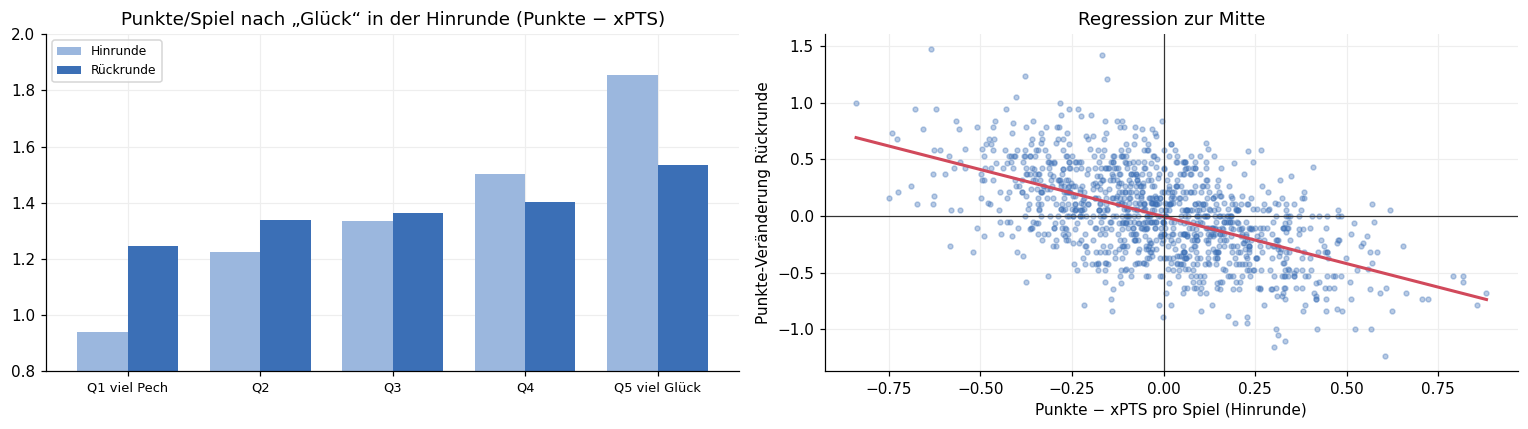

In [17]:
tv['n'] = tv.groupby(['season', 'team']).cumcount(); tv['N'] = tv.groupby(['season', 'team']).team.transform('size')
tv['halbserie'] = np.where(tv.n < tv.N / 2, 'H1', 'H2')
h = tv.groupby(['season', 'team', 'halbserie']).agg(pkt=('points', 'mean'), xpts=('expected_points', 'mean'),
                                                     gd=('goals', 'mean'), ga=('ga', 'mean'), xg=('xg', 'mean'), xga=('xga', 'mean')).unstack()
H = pd.DataFrame({'pkt1': h.pkt.H1, 'xpts1': h.xpts.H1, 'pkt2': h.pkt.H2,
                  'tordiff1': h.gd.H1 - h.ga.H1, 'xgdiff1': h.xg.H1 - h.xga.H1}).dropna()
H['glueck1'] = H.pkt1 - H.xpts1; H['veraenderung'] = H.pkt2 - H.pkt1
print(f'{len(H)} Team-Saisons\n')
print('Wie gut sagt die Hinrunde die Punkte der Rückrunde voraus? (Korrelation r)')
for c, lab in [('pkt1', 'Punkte/Spiel Hinrunde (Tabelle)'), ('tordiff1', 'Tordifferenz Hinrunde'),
               ('xpts1', 'xPTS/Spiel Hinrunde'), ('xgdiff1', 'xG-Differenz Hinrunde')]:
    print(f'  {lab:<34} r = {np.corrcoef(H[c], H.pkt2)[0,1]:.3f}')
r = stats.linregress(H.glueck1, H.veraenderung)
print(f'\nRegression zur Mitte: Veränderung Rückrunde = {r.slope:.2f} × (Punkte − xPTS der Hinrunde), p = {r.pvalue:.1g}')
H['Glücks-Quintil'] = pd.qcut(H.glueck1, 5, labels=['Q1 viel Pech', 'Q2', 'Q3', 'Q4', 'Q5 viel Glück'])
t = H.groupby('Glücks-Quintil', observed=True).agg(n=('pkt1', 'size'), punkte_minus_xpts=('glueck1', 'mean'),
                                                   pkt_hinrunde=('pkt1', 'mean'), pkt_rueckrunde=('pkt2', 'mean'), veraenderung=('veraenderung', 'mean')).round(3)
display(t)
hw = (((df.home_xg > df.away_xg) & (df.res == 'H')) | ((df.home_xg < df.away_xg) & (df.res == 'A'))).mean()
hl = (((df.home_xg > df.away_xg) & (df.res == 'A')) | ((df.home_xg < df.away_xg) & (df.res == 'H'))).mean()
print(f'Spielebene: Das Team mit dem höheren xG gewinnt {hw*100:.1f} %, spielt remis {(1-hw-hl)*100:.1f} % und verliert {hl*100:.1f} %')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(t)); w = 0.38
ax[0].bar(x - w/2, t.pkt_hinrunde, w, color='#9bb7de', label='Hinrunde')
ax[0].bar(x + w/2, t.pkt_rueckrunde, w, color=BLUE, label='Rückrunde')
ax[0].set_xticks(x); ax[0].set_xticklabels(t.index, fontsize=8.5); ax[0].legend(fontsize=8)
ax[0].set_title('Punkte/Spiel nach „Glück“ in der Hinrunde (Punkte − xPTS)'); ax[0].set_ylim(0.8, 2.0)
ax[1].scatter(H.glueck1, H.veraenderung, s=10, alpha=0.35, color=BLUE)
xs = np.linspace(H.glueck1.min(), H.glueck1.max(), 50); ax[1].plot(xs, r.intercept + r.slope * xs, color='#d1495b', lw=2)
ax[1].axhline(0, color='#333', lw=0.8); ax[1].axvline(0, color='#333', lw=0.8)
ax[1].set_xlabel('Punkte − xPTS pro Spiel (Hinrunde)'); ax[1].set_ylabel('Punkte-Veränderung Rückrunde')
ax[1].set_title('Regression zur Mitte')
plt.tight_layout(); plt.show()

**Antwort F12 – Ja. xG und xPTS sagen die Zukunft besser voraus als die Tabelle, und „Glück“ verschwindet.**
- **Vorhersage der Rückrunde** aus der Hinrunde (1.170 Team-Saisons), gemessen als Korrelation:

  | Kennzahl der Hinrunde | Korrelation mit den Punkten der Rückrunde |
  |---|---|
  | Punkte pro Spiel, also die Tabelle | r = 0,69 |
  | Tordifferenz | r = 0,71 |
  | **xPTS pro Spiel** | **r = 0,74** |
  | **xG-Differenz** | **r = 0,74** |

- **Regression zur Mitte:** Ein Team, das in der Hinrunde 0,3 Punkte pro Spiel **mehr als seine xPTS** geholt hat, verliert in der Rückrunde im Schnitt **etwa 0,25 Punkte pro Spiel**. Die Steigung liegt bei −0,83 (p < 0,001). Rund 80 % der Über- oder Unterperformance sind also **nicht nachhaltig**.
  - Die „Glücks“-Teams (Q5) fallen von 1,85 auf 1,54 Punkte pro Spiel.
  - Die „Pech“-Teams (Q1) steigen von 0,94 auf 1,25.
- Auf Spielebene gewinnt das Team mit dem höheren xG nur **59,8 %** der Spiele (25,2 % Remis, 15,0 % Niederlage). In einem einzelnen Spiel steckt also sehr viel Zufall.


---
### Kontext zu Teil A: Wie groß ist ein „großer“ Effekt? – die Geisterspiele

In [18]:
g = df.groupby('ghost')
display(pd.DataFrame({'n': g.size(), 'Heimsieg %': g.hwin.mean()*100, 'Remis %': g.draw.mean()*100,
                      'Auswärtssieg %': g.res.apply(lambda s: (s == 'A').mean()*100)}).round(1)
        .rename(index={0: 'mit Zuschauern', 1: 'Geisterspiele 03/2020–06/2021'}))
m = smf.logit('hwin ~ strdiff + C(league) + ghost', df).fit(disp=0)
print('Geisterspiel-Effekt auf Heimsieg: Koeffizient %.3f, p = %.2g' % (m.params.ghost, m.pvalues.ghost))

,n,Heimsieg %,Remis %,Auswärtssieg %
ghost,,,,
mit Zuschauern,19355,44.6,25.2,30.2
Geisterspiele 03/2020–06/2021,2234,40.2,25.1,34.7


Geisterspiel-Effekt auf Heimsieg: Koeffizient -0.215, p = 1.4e-05


**Zum Vergleich:** Ohne Zuschauer sank die Heimsiegquote um **4,4 Prozentpunkte** (p < 0,001). Dieser eine Faktor wirkt stärker als alle Wetter- und Geomerkmale zusammen. Der Heimvorteil kommt also vom **Publikum**, nicht von der Anreise oder vom Klima.

## 7 · Zusammenfassung

### Teil A – Wetter & Geodaten

| # | Frage | Ergebnis | Effektgröße |
|---|---|---|---|
| F1 | Temperatur → Tore | ✔ ja (Kälte, umgekehrtes U) | ≤ 2 °C: −7 % Tore |
| F2 | Regen → Tore | ✔ schwach | +3 % Tore, xG unverändert |
| F3 | Wind → Tore/xG | ✔ ja, robust | −2 % Tore je 10 km/h |
| F4 | Wetter → Sieger | ✘ nein | – |
| F5 | Distanz → Heimstärke | ✘ nein | OR 1,007 je 100 km (n.s.) |
| F6 | Distanz → Spielstil Gast | ◐ leicht | PPDA +0,3–0,4, xG −0,04 |
| F7 | Derby | ✘ beim Ergebnis / ◐ Tore | −3,5 % Tore (p = 0,08) |
| F8 | Breitengrad / Klimaschock | ✘ nein (Scheineffekt) | – |

### Teil B – Understat im Zeitverlauf

| # | Frage | Ergebnis | Effektgröße |
|---|---|---|---|
| F9 | Heimvorteil über die Zeit | stabil, Einbruch nur ohne Zuschauer | 45,5 % → 40,2 % → 43,5 % |
| F10 | Tore & xG über die Zeit | mehr Tore, xG steigt deutlich stärker | Tore +0,013 / xG +0,048 pro Saison |
| F11 | Pressing | weniger Pressing über die Zeit, kein eigener Erfolgsfaktor | PPDA 8,6 → 11,5 |
| F12 | xG vs. Tabelle | ✔ xPTS und xG sagen die Rückrunde besser voraus; Glück verschwindet | r 0,74 vs. 0,69; ~80 % Regression zur Mitte |

